## Name: Tushar Zhade
USC ID: 3922421673,
Github Username: tusharz7

## Question 1 a)

In [1]:
import hashlib
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed
from scipy.stats import f_oneway, norm
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix, roc_auc_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from threadpoolctl import threadpool_limits

data_dir = Path("../data/AReM")
series_names = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]


def dataset_number(path):
    return int(re.sub(r"\D", "", path.stem))


# Collect every instance file, ordered by activity folder and then dataset number
files = [
    path
    for folder in sorted(p for p in data_dir.iterdir() if p.is_dir())
    for path in sorted(folder.glob("*.csv"), key=dataset_number)
]
instances = pd.DataFrame({
    "activity": [path.parent.name for path in files],
    "dataset": [dataset_number(path) for path in files],
    "path": files,
})
instances.index = pd.RangeIndex(1, len(instances) + 1, name="Instance")
#instances["activity"].value_counts(sort=False).to_frame("Number of files")

In [2]:
# Basic QC on the raw files before any cleaning
qc_rows = []
for instance, row in instances.iterrows():
    lines = row["path"].read_text().splitlines()
    body = [line.strip() for line in lines if line.strip() and not line.startswith("#")]
    fields = [line.split(",") if "," in line else line.split() for line in body]
    times = np.array([float(f[0]) for f in fields])
    values = np.array([[float(v) for v in f[1:7]] for f in fields])
    qc_rows.append({
        "Instance": instance,
        "activity": row["activity"],
        "dataset": row["dataset"],
        "rows": len(body),
        "comma delimited": all("," in line for line in body),
        "rows with extra fields": sum(len(f) != 7 for f in fields),
        "missing values": int(np.isnan(values).sum()),
        "time gaps": int((np.diff(times) != 250).sum()),
        "avg_rss12 zeros": int((values[:, 0] == 0).sum()),
        "negative values": int((values < 0).sum()),
        "content hash": hashlib.md5(values.tobytes()).hexdigest(),
    })
qc = pd.DataFrame(qc_rows).set_index("Instance")

# Files that need attention
flagged = qc[
    (qc["rows"] != 480)
    | ~qc["comma delimited"]
    | (qc["rows with extra fields"] > 0)
    | (qc["missing values"] > 0)
    | (qc["time gaps"] > 0)
    | (qc["avg_rss12 zeros"] > 0)
    | (qc["negative values"] > 0)
]
flagged.drop(columns="content hash")

,activity,dataset,rows,comma delimited,rows with extra fields,missing values,time gaps,avg_rss12 zeros,negative values
Instance,,,,,,,,,
9,bending2,2,480,True,0,0,0,1,0
11,bending2,4,480,False,0,0,0,0,0
22,cycling,9,480,True,1,0,0,0,0
27,cycling,14,480,True,1,0,0,0,0
34,lying,6,480,True,0,0,0,1,0
51,sitting,8,479,True,0,0,1,0,0


There are no missing or negative values. A few files need minor cleaning, which is handled when the files are read and leaves the raw files unchanged:
- `bending2/dataset4.csv` is separated by spaces instead of commas, so the files are read with a separator that accepts both
- `cycling/dataset9.csv` and `cycling/dataset14.csv` have a trailing comma on their last row, which creates an empty eighth field
- `sitting/dataset8.csv` has 479 rows instead of 480 because the reading at 13500 ms is missing
- `bending2/dataset2.csv` and `lying/dataset6.csv` each have a single reading where `avg_rss12` drops to 0, which looks like a sensor dropout. These rows are kept, so `min1` is 0 for these two instances.

Six pairs of files are exact copies of each other.

In [3]:
# Read one instance file into a clean dataframe of the six time series
def load_instance(path):
    return pd.read_csv(
        path,
        comment="#",  # skip the five metadata lines
        header=None,
        sep=r"[,\s]+",  # handles both the comma and the space delimited files
        engine="python",
        usecols=range(7),  # ignores the empty field after a trailing comma
        names=["time", *series_names],
    )


time_series = {instance: load_instance(path) for instance, path in instances["path"].items()}

lengths = pd.Series({instance: len(df) for instance, df in time_series.items()})
print(f"Instances loaded: {len(time_series)}")
print(f"Columns per instance: {sorted({df.shape[1] for df in time_series.values()})}")
print(f"Rows per instance: {lengths.value_counts().to_dict()}")
print(f"Missing values after cleaning: {sum(int(df.isna().sum().sum()) for df in time_series.values())}")
time_series[1].head()

Instances loaded: 88
Columns per instance: [7]
Rows per instance: {480: 87, 479: 1}
Missing values after cleaning: 0


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


## Question 1 b)

In [4]:
# Test data: datasets 1 and 2 in bending1 and bending2 + datasets 1, 2 and 3 in the other folders
is_bending = instances["activity"].str.startswith("bending")
n_test = np.where(is_bending, 2, 3)
instances["set"] = np.where(instances["dataset"] <= n_test, "test", "train")

train_instances = instances[instances["set"] == "train"]
test_instances = instances[instances["set"] == "test"]

print(f"Train instances: {len(train_instances)}, test instances: {len(test_instances)}")
pd.crosstab(instances["activity"], instances["set"], margins=True, margins_name="Total")

Train instances: 69, test instances: 19


set,test,train,Total
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
Total,19,69,88


## Question 1 c) i

Time-domain features that are commonly used in time series classification:
- Mean, median, and mode
- Minimum, maximum, and range
- Variance, standard deviation, and root mean square (RMS)
- Skewness and kurtosis (to measure asymmetry and tail heaviness)
- Quantiles and interquartile range (IQR)

## Question 1 c) ii

In [5]:
# Extract the seven time-domain features from each of the six time series of every instance
feature_types = ["min", "max", "mean", "median", "std", "1st quart", "3rd quart"]


def extract_features(df):
    row = {}
    for i, series in enumerate(series_names, start=1):
        x = df[series]
        row[f"min{i}"] = x.min()
        row[f"max{i}"] = x.max()
        row[f"mean{i}"] = x.mean()
        row[f"median{i}"] = x.median()
        row[f"std{i}"] = x.std()  # sample standard deviation
        row[f"1st quart{i}"] = x.quantile(0.25)
        row[f"3rd quart{i}"] = x.quantile(0.75)
    return row


features = pd.DataFrame({instance: extract_features(df) for instance, df in time_series.items()}).T
features.index.name = "Instance"
feature_names = list(features.columns)

print(f"Feature table shape: {features.shape}")
with pd.option_context("display.max_columns", None):
    display(features.round(3))

Feature table shape: (88, 42)


,min1,max1,mean1,median1,std1,1st quart1,3rd quart1,min2,max2,mean2,median2,std2,1st quart2,3rd quart2,min3,max3,mean3,median3,std3,1st quart3,3rd quart3,min4,max4,mean4,median4,std4,1st quart4,3rd quart4,min5,max5,mean5,median5,std5,1st quart5,3rd quart5,min6,max6,mean6,median6,std6,1st quart6,3rd quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.625,40.50,1.477,39.25,42.000,0.0,1.30,0.359,0.430,0.323,0.00,0.500,4.00,29.50,19.041,19.250,4.463,16.00,23.250,0.0,7.23,0.833,0.50,0.966,0.000,1.120,27.25,38.25,34.311,35.00,2.188,33.000,36.00,0.00,1.92,0.571,0.43,0.583,0.000,1.300
2,38.00,45.67,42.813,42.50,1.436,42.00,43.670,0.0,1.22,0.372,0.470,0.289,0.00,0.500,2.00,29.50,20.097,21.000,3.894,19.00,22.250,0.0,5.76,0.876,0.50,1.047,0.000,1.145,27.67,38.50,33.025,33.00,1.995,32.000,34.50,0.00,3.11,0.571,0.43,0.601,0.000,1.300
3,35.00,47.40,43.954,44.33,1.559,43.00,45.000,0.0,1.70,0.426,0.470,0.339,0.00,0.500,6.50,29.75,22.122,23.000,3.031,19.75,24.000,0.0,4.44,0.497,0.43,0.551,0.000,0.830,29.00,38.50,35.588,36.00,2.000,35.362,36.50,0.00,1.79,0.493,0.43,0.514,0.000,0.940
4,33.00,47.75,42.180,43.50,3.671,39.15,45.000,0.0,3.00,0.696,0.500,0.631,0.00,1.120,8.50,30.00,22.184,23.000,3.810,20.50,24.372,0.0,5.15,0.990,0.83,0.954,0.430,1.300,20.00,38.67,33.494,35.00,3.849,30.458,36.33,0.00,2.18,0.614,0.50,0.524,0.000,1.000
5,33.00,45.75,41.678,41.75,2.243,41.33,42.750,0.0,2.83,0.536,0.500,0.405,0.43,0.710,3.00,28.25,19.007,19.125,4.087,16.50,22.062,0.0,6.42,0.842,0.50,0.929,0.430,1.120,23.67,37.50,29.857,30.00,2.411,28.458,31.25,0.00,1.79,0.383,0.43,0.389,0.000,0.500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.587,34.25,4.651,30.25,37.000,0.0,14.67,4.577,4.260,2.461,2.87,6.105,7.33,23.25,15.318,15.330,2.970,13.25,17.270,0.0,9.00,3.227,3.10,1.647,2.050,4.260,6.33,25.00,15.892,16.00,3.284,13.730,18.25,0.00,8.32,3.260,3.11,1.640,2.050,4.322
85,19.75,45.50,34.323,35.25,4.752,31.00,38.000,0.0,13.47,4.456,3.900,2.599,2.49,5.970,6.25,22.25,15.210,15.250,2.711,13.50,17.000,0.0,9.00,3.277,3.11,1.500,2.170,4.390,6.25,23.25,15.550,15.75,3.120,13.500,17.75,0.00,9.67,3.433,3.20,1.733,2.157,4.565
86,19.50,46.00,34.546,35.25,4.842,31.25,37.812,0.0,12.47,4.372,4.135,2.360,2.49,5.800,7.00,22.67,15.186,15.250,2.758,13.25,17.000,0.0,8.34,3.029,2.86,1.665,1.790,4.110,7.00,22.75,15.760,15.75,2.823,14.000,17.75,0.00,10.00,3.338,3.08,1.657,2.160,4.335


The new data set has 88 rows (one per instance) and 42 columns (7 features for each of the 6 time series). The number after each feature name is the time series it came from: 1 = `avg_rss12`, 2 = `var_rss12`, 3 = `avg_rss13`, 4 = `var_rss13`, 5 = `avg_rss23`, 6 = `var_rss23`.
Didn't normalize/standardize.

## Question 1 c) iii

In [6]:
# Standard deviation of each feature across the 88 instances
feature_std = features.std()  # sample standard deviation (ddof = 1)

# 90% bootstrap confidence interval: resample the 88 instances with replacement 1000 times
n_bootstrap = 1000
rng = np.random.default_rng(552)
n_instances = len(features)
resample_index = rng.integers(0, n_instances, size=(n_bootstrap, n_instances))
bootstrap_std = features.to_numpy()[resample_index].std(axis=1, ddof=1)  # shape: (1000, 42)

ci_lower, ci_upper = np.percentile(bootstrap_std, [5, 95], axis=0)
std_table = pd.DataFrame({
    "Std": feature_std,
    "90% CI lower": ci_lower,
    "90% CI upper": ci_upper,
}, index=feature_names)
std_table.index.name = "Feature"

with pd.option_context("display.max_rows", None):
    display(std_table.round(4))

,Std,90% CI lower,90% CI upper
Feature,,,
min1,9.5700,8.2353,10.6892
max1,4.3944,3.3326,5.3047
mean1,5.3357,4.7048,5.8863
median1,5.4401,4.7922,6.0093
std1,1.7722,1.5720,1.9438
1st quart1,6.1536,5.5678,6.6341
3rd quart1,5.1389,4.3299,5.8612
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6400,5.3919


## Question 1 c) iv

In [7]:
# One-way ANOVA F-statistic of each feature across the seven activities (training data only)
train_features = features.loc[train_instances.index]
train_activity = train_instances["activity"]

f_scores = {}
for feature in feature_names:
    groups = [train_features.loc[train_activity == a, feature] for a in train_activity.unique()]
    # A feature that is the same for every instance cannot separate anything
    f_scores[feature] = np.nan if train_features[feature].nunique() == 1 else f_oneway(*groups).statistic

f_table = pd.DataFrame(
    {series: [f_scores[f"{t}{i}"] for t in feature_types] for i, series in enumerate(series_names, start=1)},
    index=feature_types,
)
f_table["Mean F"] = f_table[series_names].mean(axis=1)
f_table["Mean rank"] = f_table[series_names].rank(ascending=False).mean(axis=1)
f_table.sort_values("Mean F", ascending=False).round(1)

,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,Mean F,Mean rank
mean,15.9,900.2,26.4,651.8,33.4,581.5,368.2,2.2
3rd quart,8.5,807.0,28.1,561.9,32.2,664.8,350.4,2.8
median,17.5,477.0,19.4,800.8,28.6,563.1,317.7,3.2
1st quart,21.4,265.5,21.2,244.8,25.5,346.3,154.1,4.0
std,9.1,360.9,15.2,128.6,7.8,133.4,109.2,5.5
max,1.5,47.7,31.7,29.3,37.0,33.0,30.0,4.5
min,11.0,NaN,22.7,NaN,24.1,0.8,14.6,5.2


In [8]:
# How much the feature types overlap: average |correlation| between two feature types over the six time series
def mean_abs_correlation(type_a, type_b):
    correlations = []
    for i in range(1, 7):
        a, b = train_features[f"{type_a}{i}"], train_features[f"{type_b}{i}"]
        if a.nunique() > 1 and b.nunique() > 1:
            correlations.append(abs(a.corr(b)))
    return np.mean(correlations)


redundancy = pd.DataFrame(
    [[mean_abs_correlation(a, b) for b in feature_types] for a in feature_types],
    index=feature_types,
    columns=feature_types,
)
redundancy.round(2)

,min,max,mean,median,std,1st quart,3rd quart
min,1.00,0.36,0.59,0.57,0.40,0.60,0.52
max,0.36,1.00,0.79,0.75,0.63,0.71,0.82
mean,0.59,0.79,1.00,0.99,0.60,0.98,0.98
median,0.57,0.75,0.99,1.00,0.61,0.98,0.96
std,0.40,0.63,0.60,0.61,1.00,0.66,0.57
1st quart,0.60,0.71,0.98,0.98,0.66,1.00,0.93
3rd quart,0.52,0.82,0.98,0.96,0.57,0.93,1.00


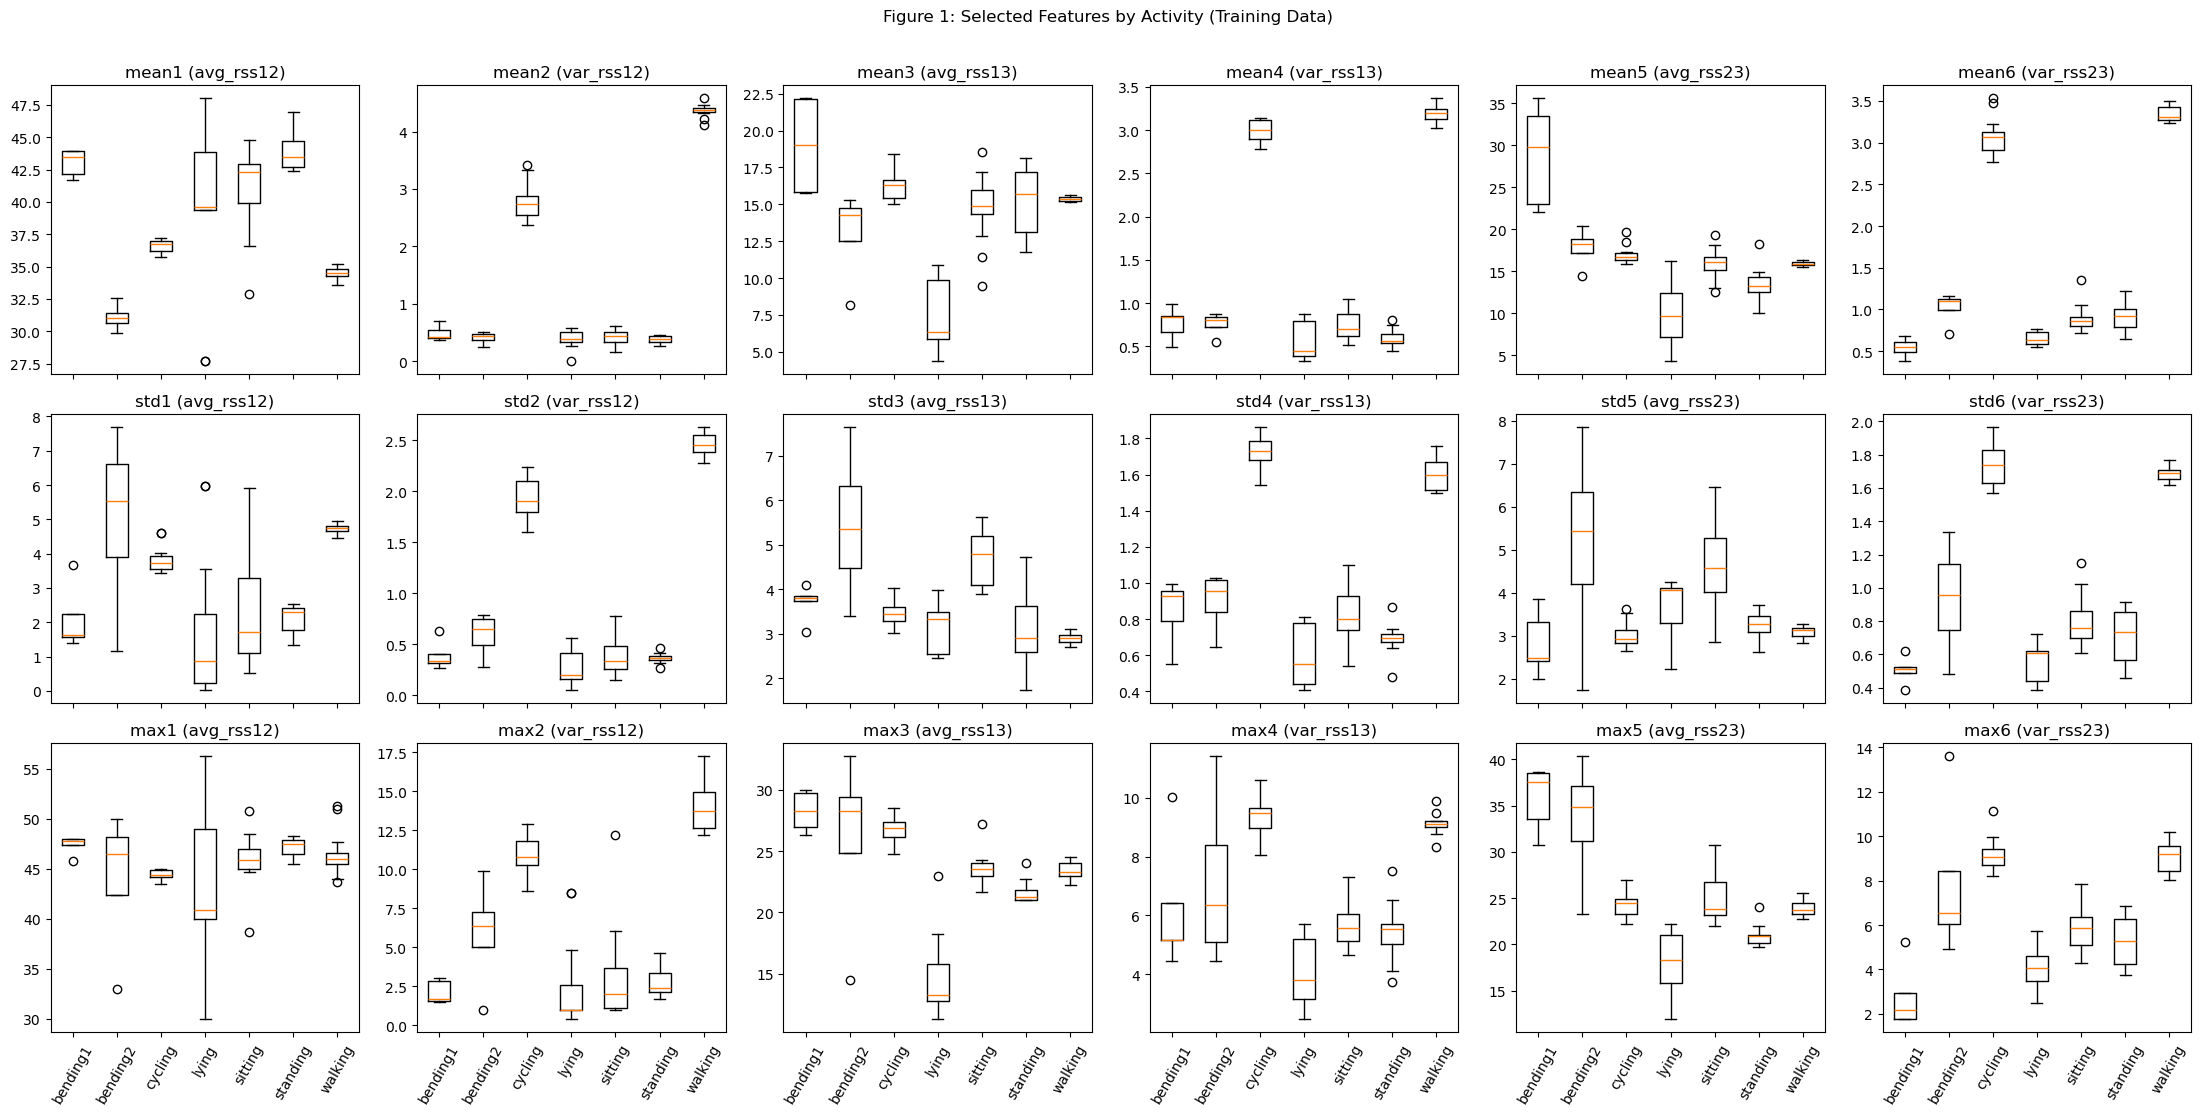

In [9]:
# Boxplots of the three selected feature types by activity (training data)
selected_types = ["mean", "std", "max"]
activities = list(train_activity.unique())

fig, axes = plt.subplots(len(selected_types), 6, figsize=(22, 11), sharex=True)
for r, feature_type in enumerate(selected_types):
    for c, series in enumerate(series_names):
        feature = f"{feature_type}{c + 1}"
        ax = axes[r, c]
        ax.boxplot([train_features.loc[train_activity == a, feature] for a in activities])
        ax.set_xticks(range(1, len(activities) + 1), labels=activities, rotation=60)
        ax.set_title(f"{feature} ({series})")
fig.suptitle("Figure 1: Selected Features by Activity (Training Data)", y=1.01)
plt.tight_layout()
plt.show()

I'd select mean, standard deviation, and maximum

The choice is based on the training data only, using two questions: how well does a feature type separate the seven activities (used one-way ANOVA F-statistic for this), and how much new information does it add to the features already chosen (correlation between feature types).

## Question 2 a) i

{'Other': 60, 'Bending': 9}


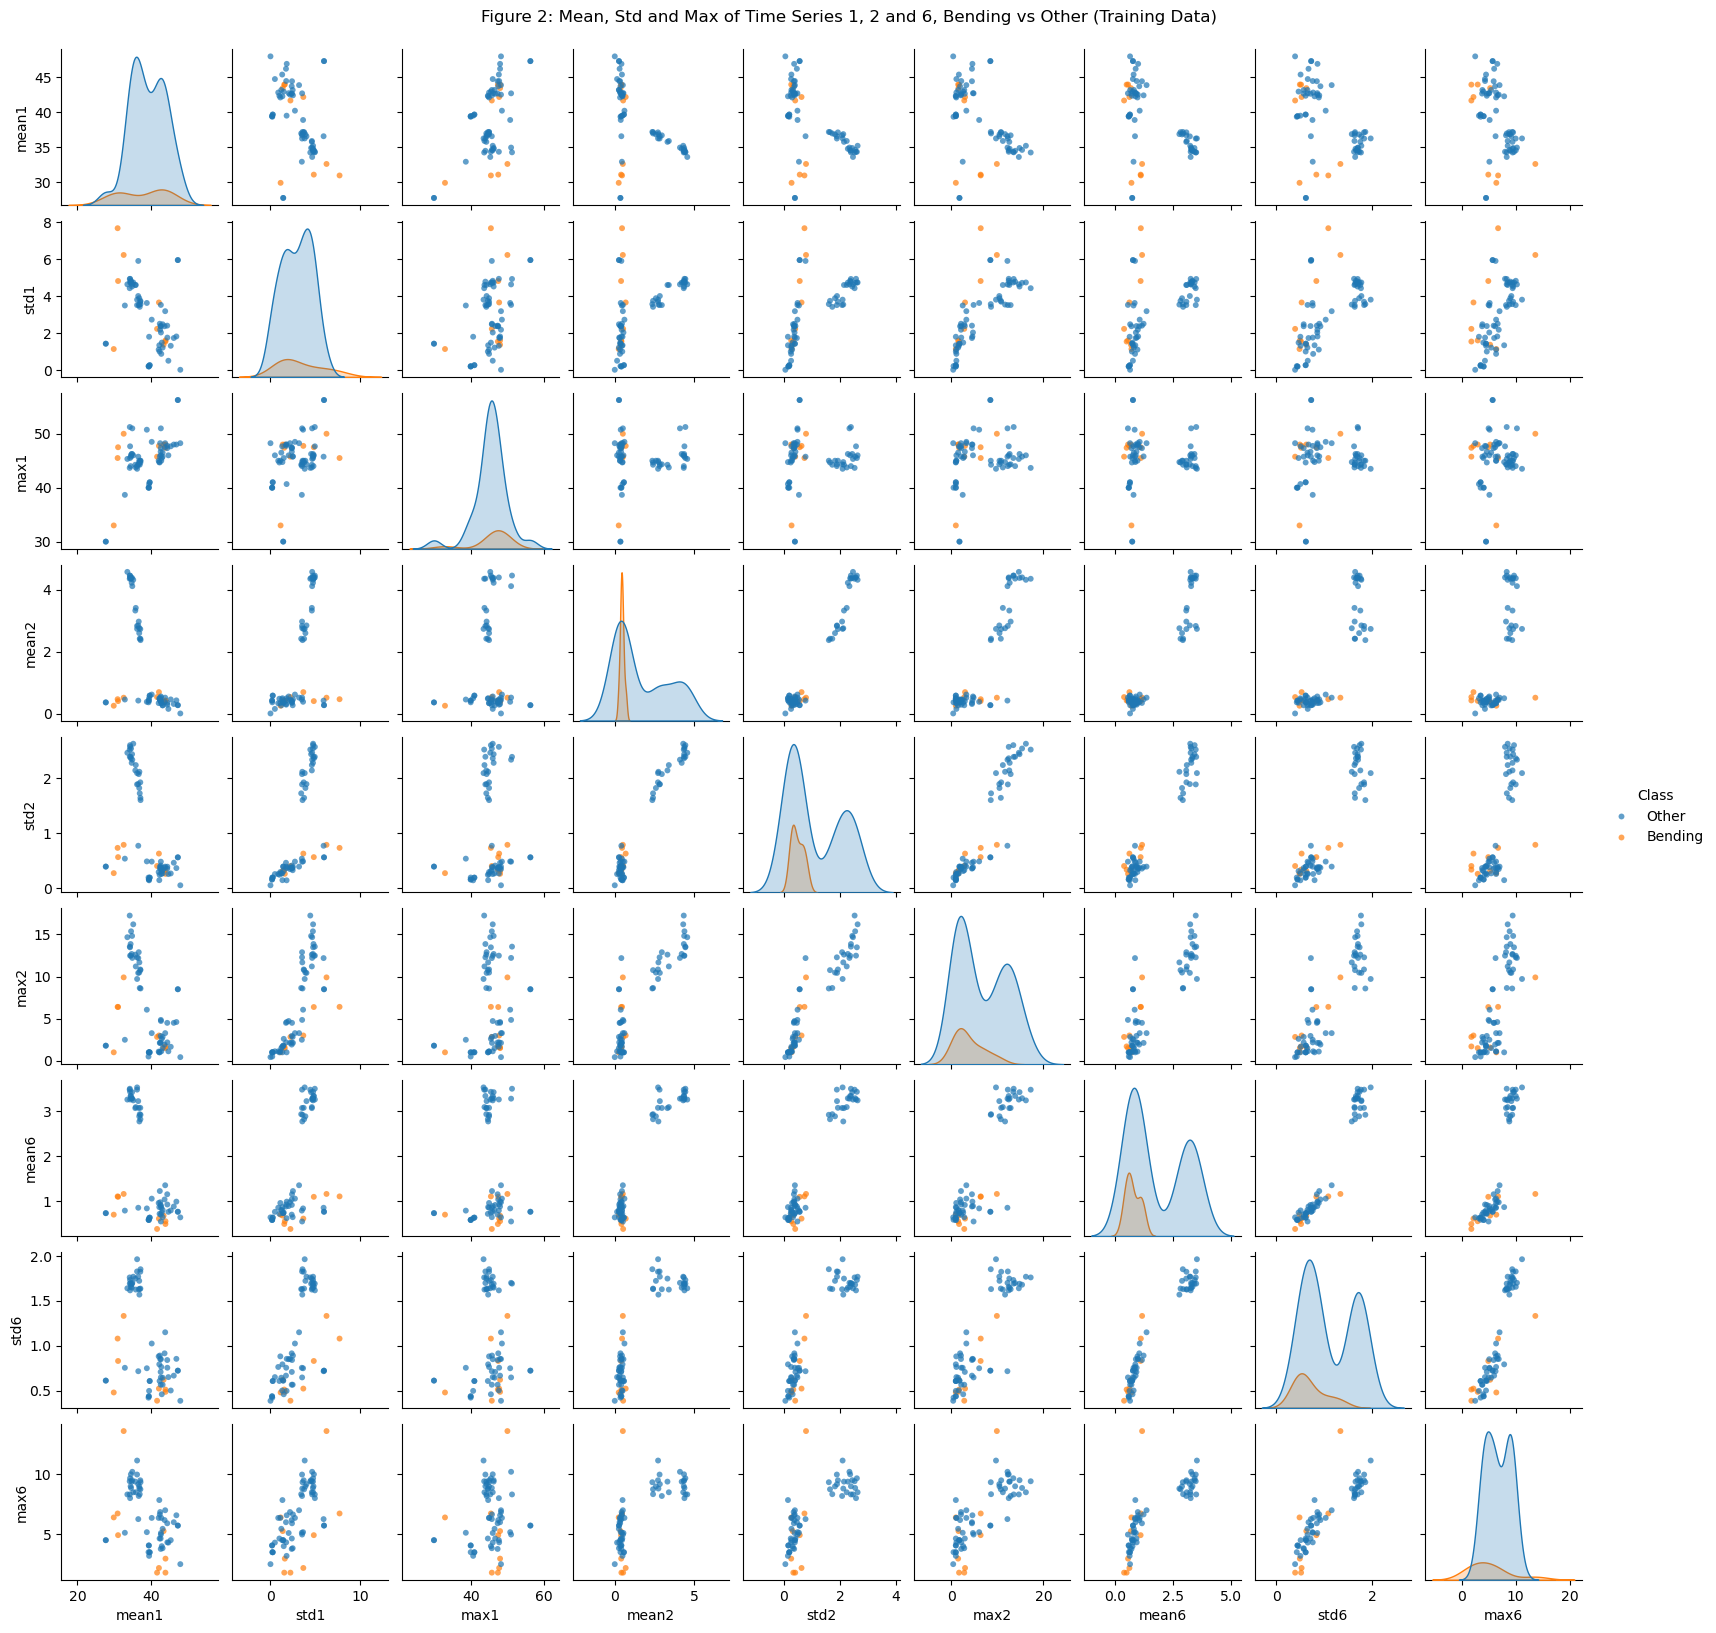

In [10]:
# Binary problem on the training set: bending (bending1 + bending2) vs all other activities
train_class = np.where(train_activity.str.startswith("bending"), "Bending", "Other")
class_colors = {"Bending": "tab:orange", "Other": "tab:blue"}

# Features selected in 1 c) iv, from time series 1, 2 and 6
plot_series = [1, 2, 6]
plot_features = [f"{t}{i}" for i in plot_series for t in selected_types]

scatter_data = train_features[plot_features].assign(Class=train_class)
print(pd.Series(train_class).value_counts().to_dict())

grid = sns.pairplot(
    scatter_data,
    hue="Class",
    hue_order=["Other", "Bending"],
    palette=class_colors,
    height=1.8,
    plot_kws={"s": 18, "alpha": 0.7, "edgecolor": "none"},
)
grid.figure.suptitle("Figure 2: Mean, Std and Max of Time Series 1, 2 and 6, Bending vs Other (Training Data)", y=1.01)
plt.show()

The training set has 9 bending and 60 other instances.
- Time series 2 and 6 (`var_rss12`, `var_rss23`) split the instances into two clear groups: the moving activities (cycling, walking) with large means, standard deviations and maxima, and the still ones with small values. The bending instances fall in the still group, so these features separate bending from cycling and walking but not from lying, sitting and standing.
- `mean1` separates part of the bending class: the 4 bending2 instances have a low `mean1` (about 30 to 33), which shows up in the `mean1` vs `mean6` and `mean1` vs `std2` panels as bending points in the lower left corner.
- No single pair of features separates the two classes completely. The 5 bending1 instances have a `mean1` of about 42 to 44, the same range as the other still activities, and they overlap with them in every panel.

## Question 2 a) ii

In [11]:
# Break every time series into l parts of approximately equal length and extract the features of each part
def extract_split_features(df, n_parts):
    row = {}
    for part, rows in enumerate(np.array_split(np.arange(len(df)), n_parts), start=1):
        for name, value in extract_features(df.iloc[rows]).items():
            row[f"{name}_part{part}"] = value
    return row


train_split_features = pd.DataFrame(
    {instance: extract_split_features(time_series[instance], 2) for instance in train_instances.index}
).T
train_split_features.index.name = "Instance"
print(f"Training feature table with l = 2: {train_split_features.shape}")
train_split_features.head()

Training feature table with l = 2: (69, 84)


,min1_part1,max1_part1,mean1_part1,median1_part1,std1_part1,1st quart1_part1,3rd quart1_part1,min2_part1,max2_part1,mean2_part1,...,std5_part2,1st quart5_part2,3rd quart5_part2,min6_part2,max6_part2,mean6_part2,median6_part2,std6_part2,1st quart6_part2,3rd quart6_part2
Instance,,,,,,,,,,,,,,,,,,,,,
3,36.50,46.50,44.057167,44.50,1.556971,43.2500,45.00,0.0,1.50,0.381042,...,2.298693,33.00,36.2500,0.0,1.50,0.388333,0.00,0.478528,0.0000,0.71
4,33.75,47.75,43.278875,45.00,3.473355,42.0000,45.25,0.0,3.00,0.673292,...,3.760118,28.75,33.7500,0.0,2.18,0.586083,0.47,0.491873,0.0000,0.87
5,33.00,45.75,41.621208,42.33,3.118644,39.6525,44.25,0.0,2.83,0.623083,...,2.062647,28.31,30.5625,0.0,1.50,0.347500,0.43,0.363144,0.0000,0.50
6,39.00,48.00,44.117042,45.00,1.359836,43.5000,45.00,0.0,1.30,0.250042,...,1.881721,22.50,23.7500,0.0,4.06,0.543875,0.50,0.473445,0.4300,0.71
7,36.67,45.00,43.486208,43.71,1.281976,42.3300,44.50,0.0,1.30,0.378667,...,1.929494,21.00,23.5000,0.0,2.96,0.585750,0.50,0.487918,0.4225,0.83


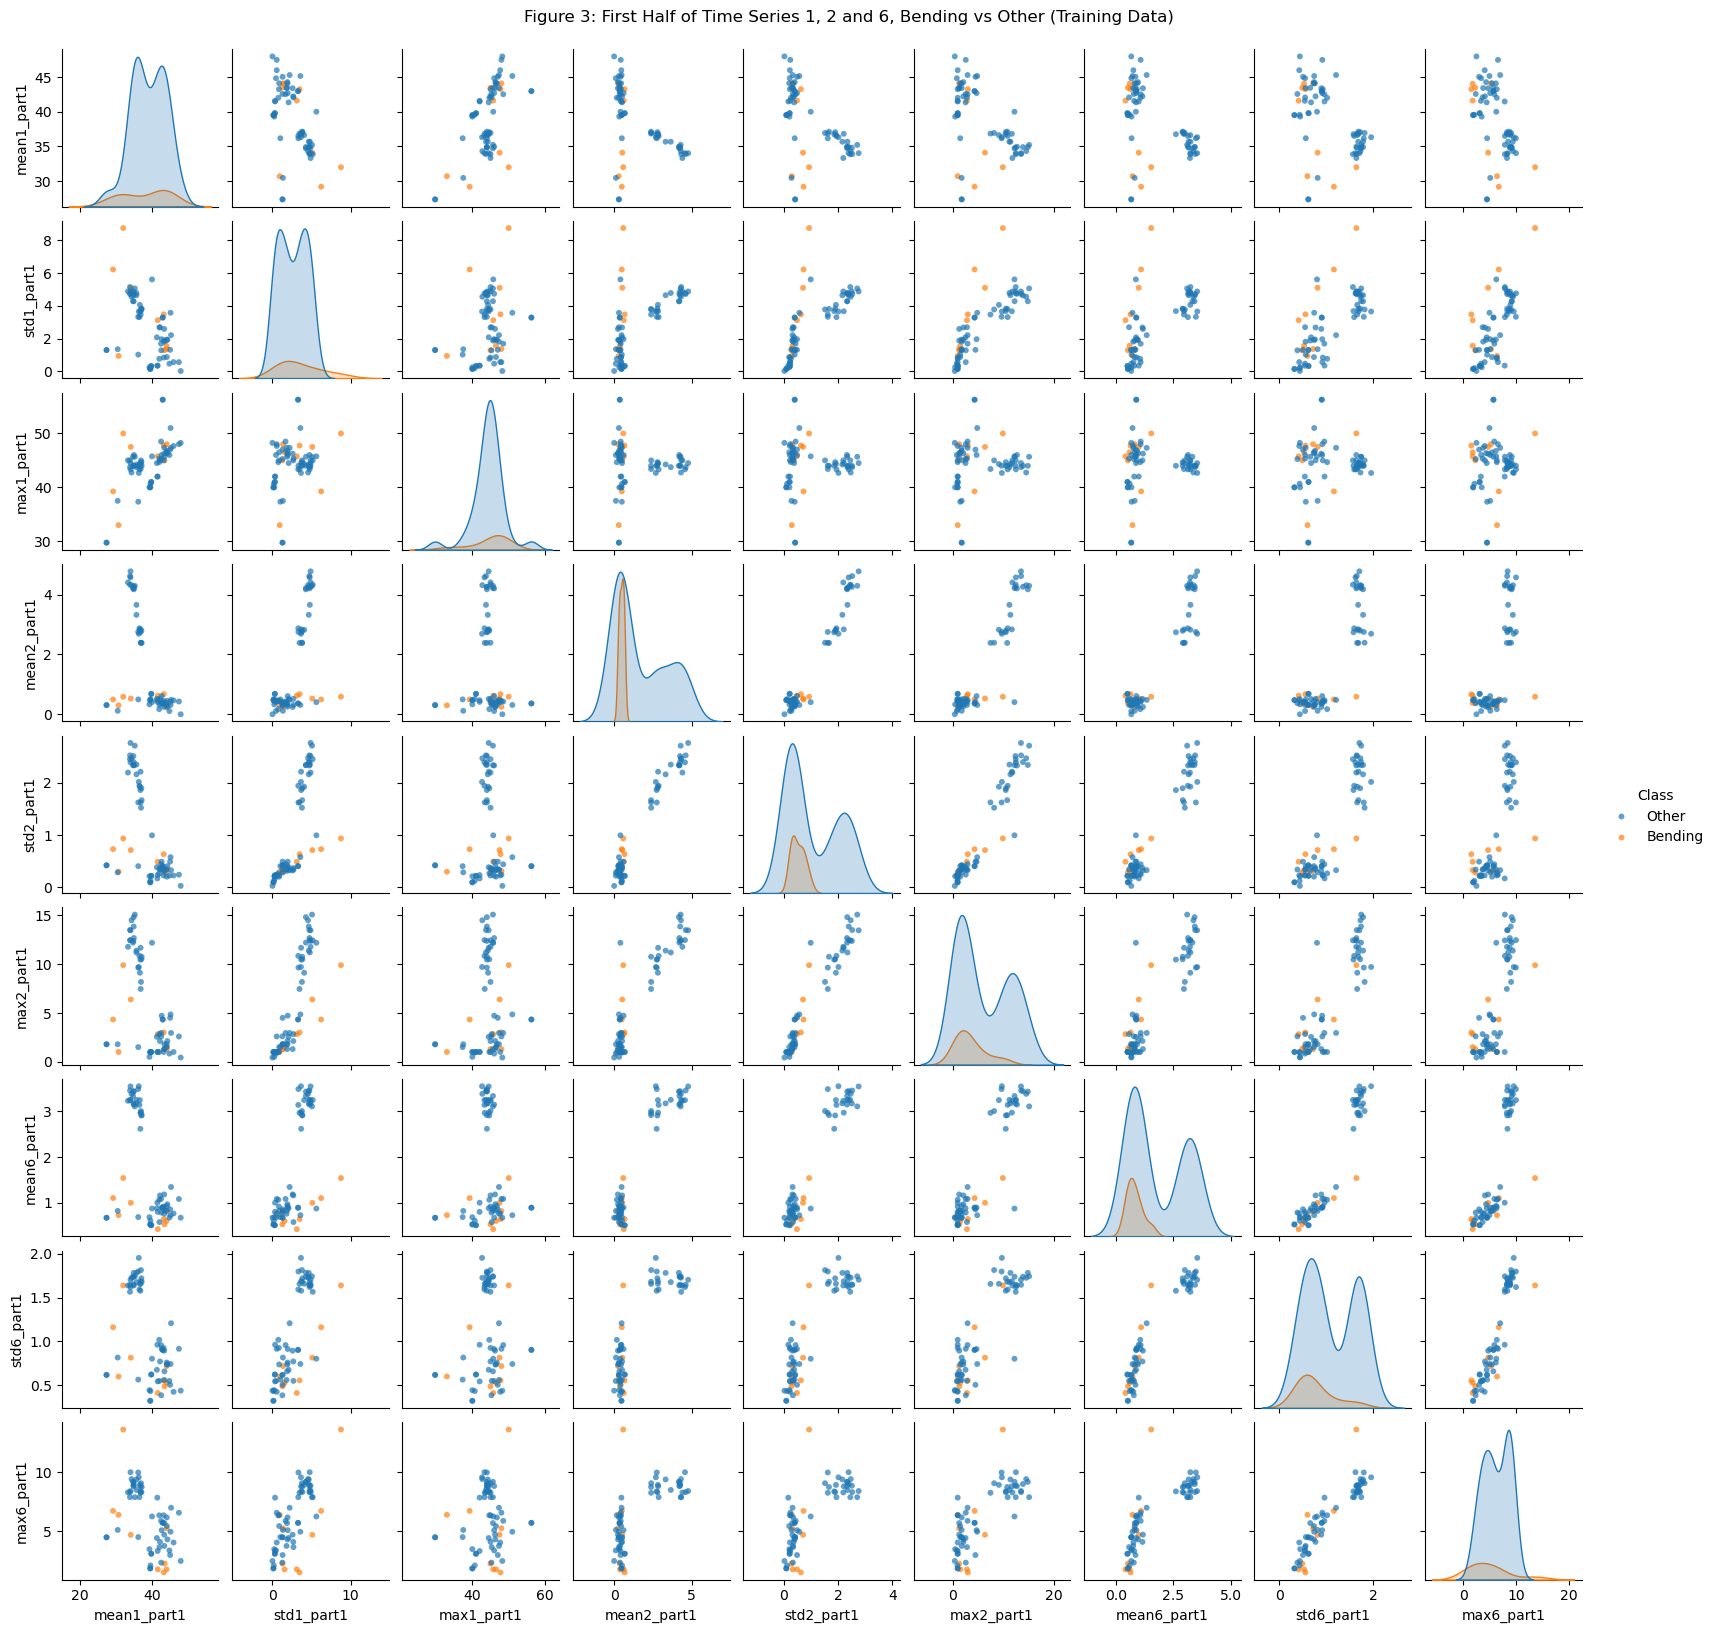

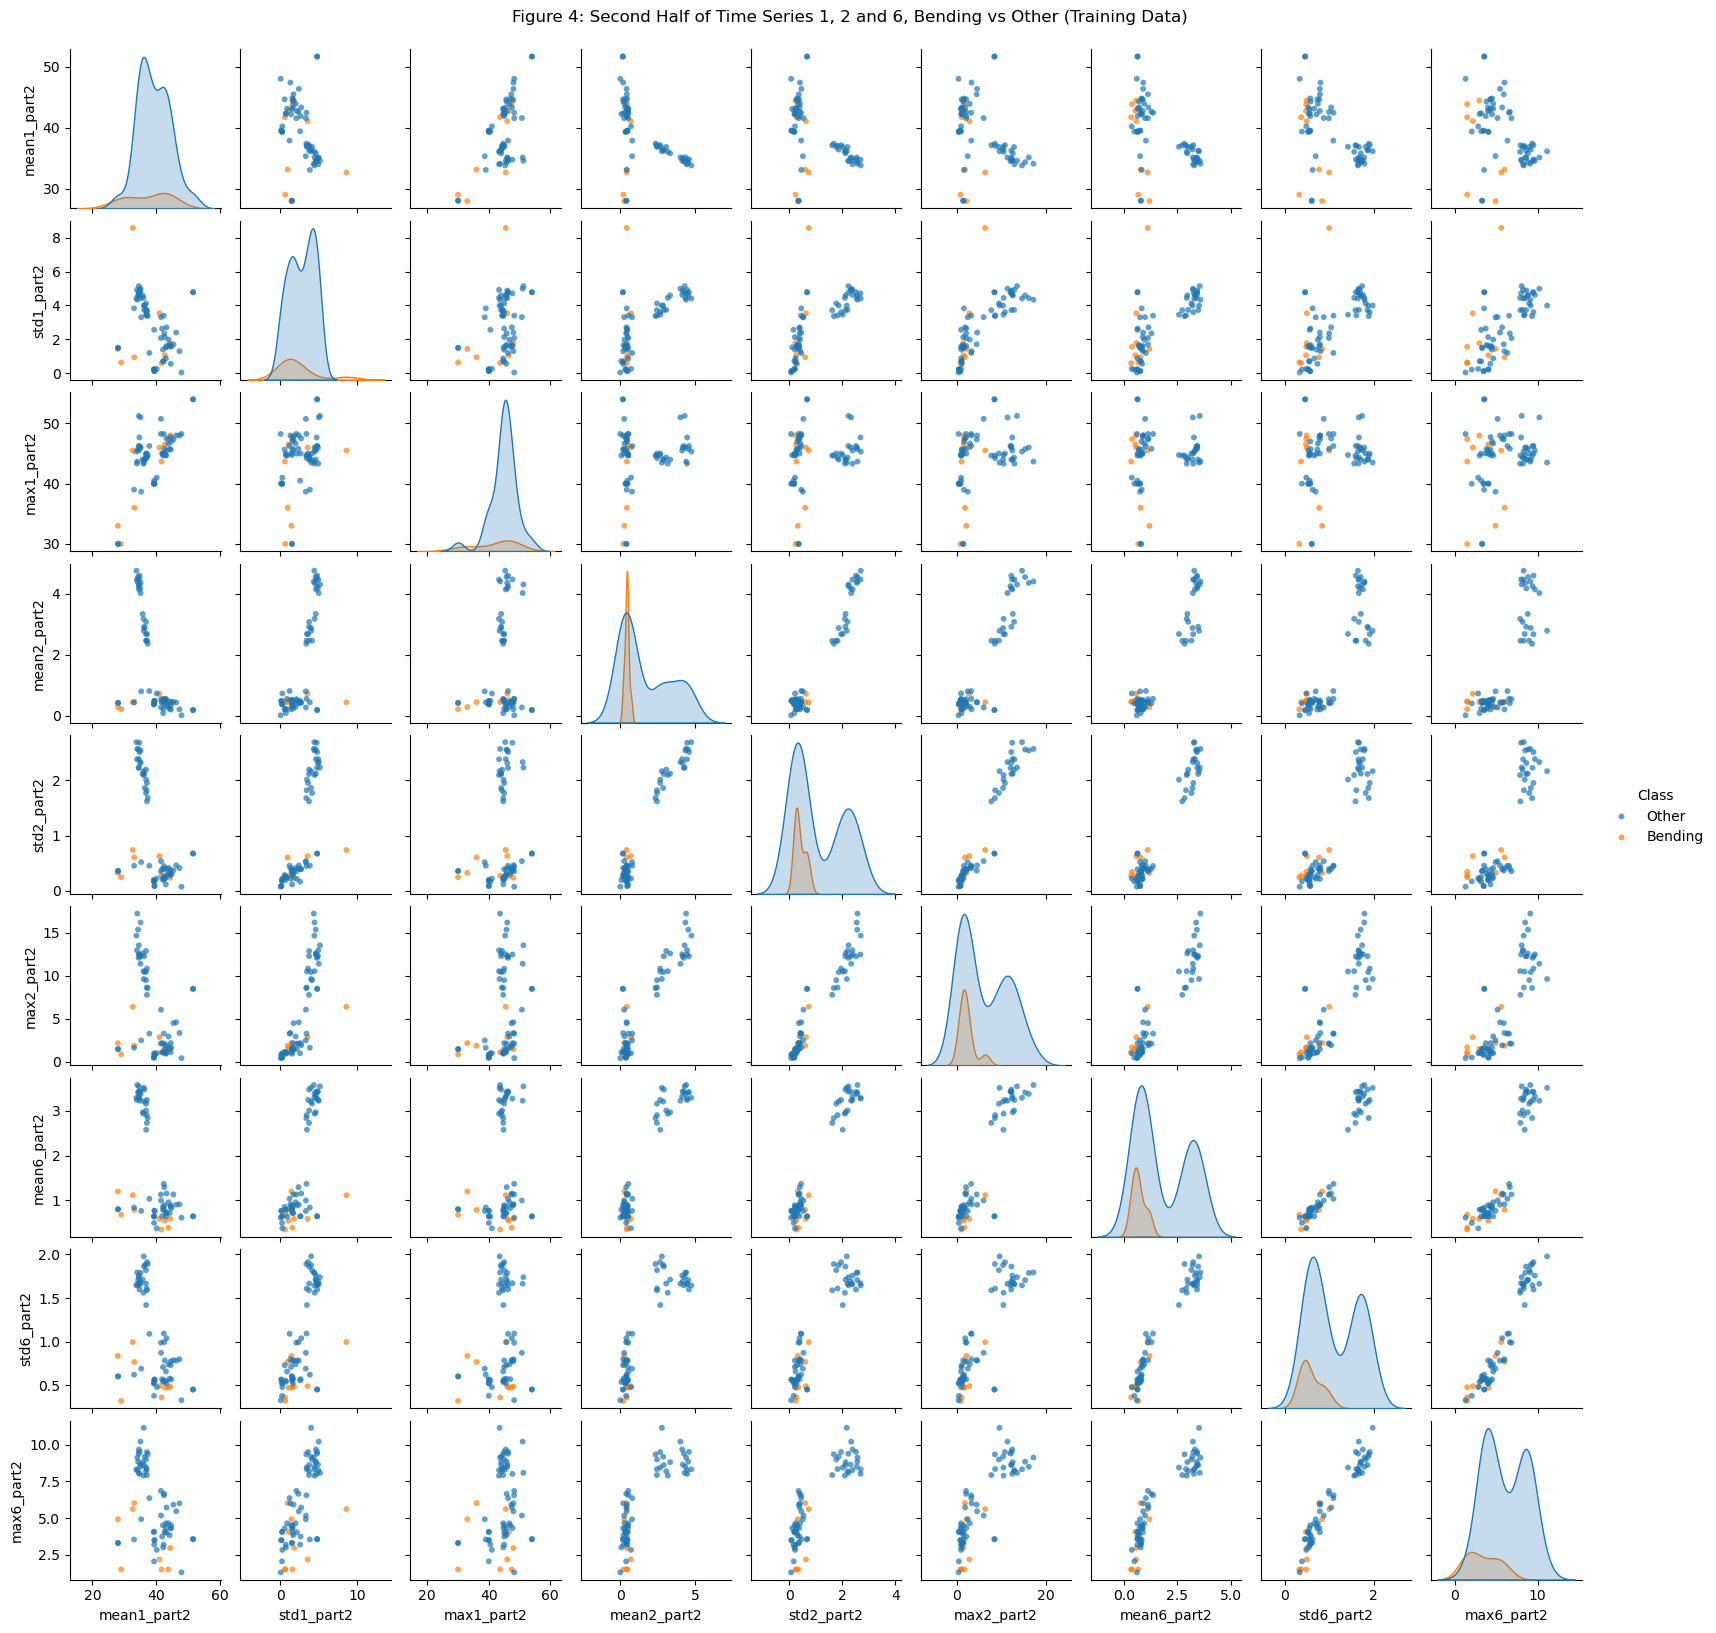

In [12]:
# Same scatter plots as 2 a) i, once for each half of the time series
for part in (1, 2):
    part_features = [f"{feature}_part{part}" for feature in plot_features]
    part_data = train_split_features[part_features].assign(Class=train_class)
    grid = sns.pairplot(
        part_data,
        hue="Class",
        hue_order=["Other", "Bending"],
        palette=class_colors,
        height=1.8,
        plot_kws={"s": 18, "alpha": 0.7, "edgecolor": "none"},
    )
    half = "First" if part == 1 else "Second"
    grid.figure.suptitle(
        f"Figure {2 + part}: {half} Half of Time Series 1, 2 and 6, Bending vs Other (Training Data)", y=1.01
    )
    plt.show()

There is no considerable difference from 2 a) i. Both halves show the same groups as the full time series: the moving activities are separated by the features of series 2 and 6, and the bending instances overlap with the still activities except for the lower `mean1` of the bending2 instances. The features of each half are a little noisier because they are computed from 240 values instead of 480 (for example, a few points move further away from their group in the `std1` and `max2` panels), but the relative positions of the two classes do not change. This suggests the activities are fairly stationary over the two minutes of each recording.

## Question 2 a) iii

In [13]:
# Mean, std and max (the features selected in 1 c) iv) of every part of all six time series, for l = 1 to 20
def split_feature_table(n_parts, instance_ids):
    rows = {}
    for instance in instance_ids:
        values = time_series[instance][series_names].to_numpy()
        row = {}
        for part, idx in enumerate(np.array_split(np.arange(len(values)), n_parts), start=1):
            chunk = values[idx]
            for i in range(len(series_names)):
                row[f"mean{i + 1}_part{part}"] = chunk[:, i].mean()
                row[f"std{i + 1}_part{part}"] = chunk[:, i].std(ddof=1)  # sample standard deviation, as in 1 c) ii
                row[f"max{i + 1}_part{part}"] = chunk[:, i].max()
        rows[instance] = row
    table = pd.DataFrame(rows).T
    table.index.name = "Instance"
    return table


l_values = range(1, 21)
split_tables = {l: split_feature_table(l, instances.index) for l in l_values}

# Check against the 2 a) ii features for l = 2
check = train_split_features[split_tables[2].columns]
assert np.allclose(split_tables[2].loc[train_instances.index], check)

print({l: split_tables[l].shape[1] for l in (1, 2, 5, 10, 20)}, "features for some values of l")

{1: 18, 2: 36, 5: 90, 10: 180, 20: 360} features for some values of l


In [14]:
# Binary target: 1 = bending, 0 = other
y_train = (train_class == "Bending").astype(int)

# Stratified 5-fold CV: every fold keeps about the same share of bending instances (9 of 69 overall)
n_folds = 5
folds = list(StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=552).split(np.zeros(len(y_train)), y_train))
print("Bending instances in each validation fold:", [int(y_train[val].sum()) for _, val in folds])

max_p = 20  # largest number of features RFE keeps (each training fold has only about 7 bending instances)


def make_logistic():
    # No L2 penalty (footnote 3). The classes can be linearly separable, so the solver is stopped
    # after max_iter iterations instead of letting the coefficients grow without bound (footnote 5).
    return LogisticRegression(penalty=None, max_iter=100)


def cv_accuracy_for_l(l, X, y):
    n_p = min(X.shape[1], max_p)
    accuracy = np.zeros((n_folds, n_p))
    with threadpool_limits(1), warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)  # expected when the classes are separable
        for fold, (fit_idx, val_idx) in enumerate(folds):
            # Standardize and run RFE on the training part of the fold only
            scaler = StandardScaler().fit(X[fit_idx])
            X_fit, X_val = scaler.transform(X[fit_idx]), scaler.transform(X[val_idx])
            # One RFE run down to 1 feature gives the nested RFE subsets for every p: ranking <= p
            ranking = RFE(make_logistic(), n_features_to_select=1).fit(X_fit, y[fit_idx]).ranking_
            for p in range(1, n_p + 1):
                keep = ranking <= p
                model = make_logistic().fit(X_fit[:, keep], y[fit_idx])
                accuracy[fold, p - 1] = model.score(X_val[:, keep], y[val_idx])
    return [
        {"l": l, "p": p, "CV accuracy": accuracy[:, p - 1].mean(), "CV accuracy std": accuracy[:, p - 1].std()}
        for p in range(1, n_p + 1)
    ]


# Each value of l runs in parallel (takes about a minute)
cv_rows = Parallel(n_jobs=-1)(
    delayed(cv_accuracy_for_l)(l, split_tables[l].loc[train_instances.index].to_numpy(), y_train) for l in l_values
)
cv_results = pd.DataFrame([row for rows in cv_rows for row in rows])

# Best pair: highest CV accuracy; ties go to the fewest features, then the smallest l
ranked = cv_results.sort_values(["CV accuracy", "p", "l"], ascending=[False, True, True])
best_l, best_p = int(ranked.iloc[0]["l"]), int(ranked.iloc[0]["p"])
print(f"Best (l, p) = ({best_l}, {best_p}), CV accuracy = {ranked.iloc[0]['CV accuracy']:.4f}")
ranked.head(10).round(4)

Bending instances in each validation fold: [2, 2, 2, 2, 1]


Best (l, p) = (19, 6), CV accuracy = 0.9857


,l,p,CV accuracy,CV accuracy std
363,19,6,0.9857,0.0286
153,8,16,0.9857,0.0286
154,8,17,0.9857,0.0286
155,8,18,0.9857,0.0286
38,3,1,0.9714,0.0350
219,12,2,0.9714,0.0350
40,3,3,0.9714,0.0350
220,12,3,0.9714,0.0350
221,12,4,0.9714,0.0350
364,19,7,0.9714,0.0350


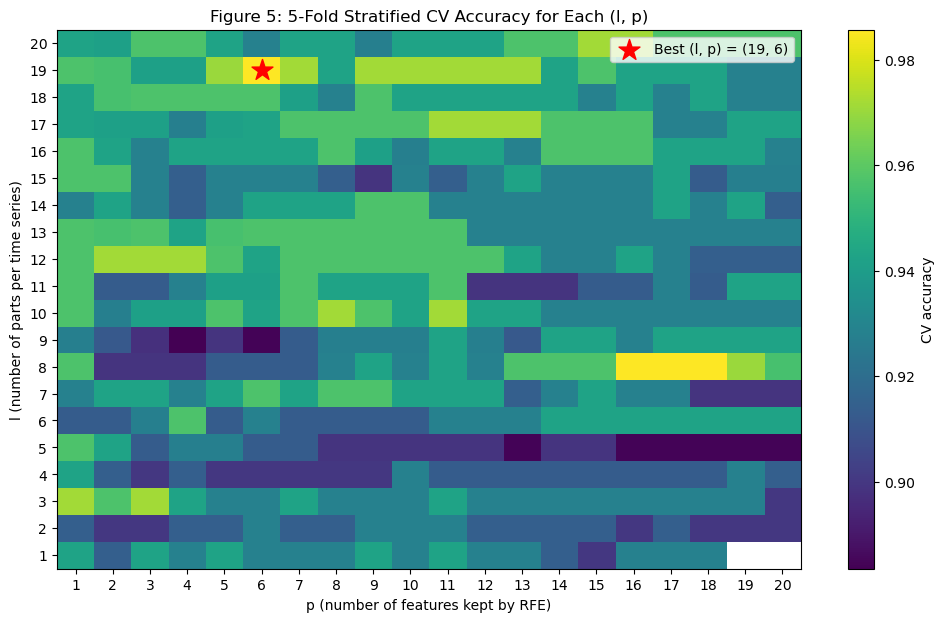

In [15]:
# CV accuracy for every (l, p) pair
accuracy_grid = cv_results.pivot(index="l", columns="p", values="CV accuracy")

fig, ax = plt.subplots(figsize=(12, 7))
image = ax.imshow(accuracy_grid, cmap="viridis", aspect="auto", origin="lower")
ax.set_xticks(range(accuracy_grid.shape[1]), labels=accuracy_grid.columns)
ax.set_yticks(range(accuracy_grid.shape[0]), labels=accuracy_grid.index)
ax.scatter(accuracy_grid.columns.get_loc(best_p), accuracy_grid.index.get_loc(best_l), marker="*", s=250, color="red", label=f"Best (l, p) = ({best_l}, {best_p})")
ax.set_xlabel("p (number of features kept by RFE)")
ax.set_ylabel("l (number of parts per time series)")
ax.set_title("Figure 5: 5-Fold Stratified CV Accuracy for Each (l, p)")
ax.legend(loc="upper right")
fig.colorbar(image, ax=ax, label="CV accuracy")
plt.show()

**Method.** Instead of pruning features by their p-values, I used the alternative the question allows: backward selection with recursive feature elimination (RFE), where p is the number of features RFE keeps.

**Right and wrong way to cross-validate.** The wrong way is to choose the features first using all the training data (running RFE or the p-value pruning on all 69 instances) and then cross-validate only the final logistic regression on those features. The selection step has already seen the labels of the validation folds, so the CV accuracy is too optimistic. The right way, used here, is to repeat every step that looks at the labels inside each fold: for each fold, standardization and RFE are fit on the training part only, and the model with the selected features is scored on the held-out part. Breaking the time series into l parts does not use the labels, so the feature tables can be built once for each l before cross-validation.

**Stratified CV.** Stratified k-fold CV splits the data so that every fold has about the same proportion of each class as the full training set. Only 9 of the 69 training instances are bending, so a plain random 5-fold split could leave a fold with no bending instances to validate on. With stratification, each validation fold here has 1 or 2 bending instances.

**Result.** The best pair is **l = 19, p = 6**, with a CV accuracy of 98.6% (one instance misclassified across the five folds). Figure 5 shows that the accuracy surface is noisy: most pairs score between 90% and 97%, and the gap between the best pair and many others is one or two instances. With only 69 training instances the choice of (l, p) is not very stable, and simpler models such as l = 3, p = 1 (97.1%) are almost as good.

## Question 2 a) iv

In [16]:
# Refit on the full training set with the best (l, p): standardize, RFE down to p features, logistic regression
X_train_best = split_tables[best_l].loc[train_instances.index]
final_scaler = StandardScaler().fit(X_train_best)
X_train_best_std = final_scaler.transform(X_train_best)

with threadpool_limits(1), warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    final_rfe = RFE(make_logistic(), n_features_to_select=best_p).fit(X_train_best_std, y_train)
    selected_features = list(X_train_best.columns[final_rfe.support_])
    final_model = make_logistic().fit(X_train_best_std[:, final_rfe.support_], y_train)

print(f"l = {best_l}, selected features: {selected_features}")

l = 19, selected features: ['mean5_part3', 'max5_part3', 'max1_part11', 'std4_part14', 'std5_part18', 'std5_part19']


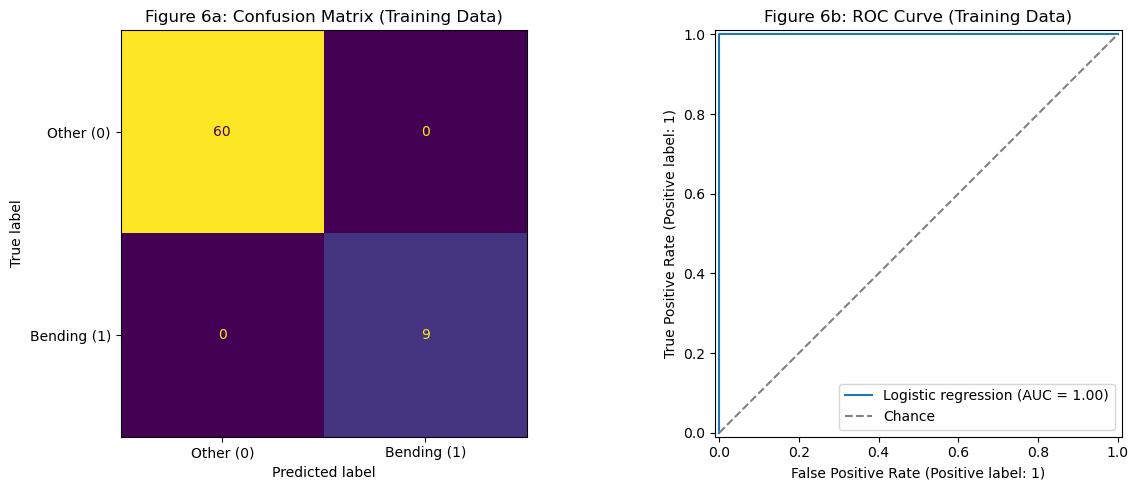

Training accuracy = 1.0000, AUC = 1.0000


In [17]:
# Confusion matrix and ROC curve on the training data
train_prob = final_model.predict_proba(X_train_best_std[:, final_rfe.support_])[:, 1]
train_pred = (train_prob >= 0.5).astype(int)
train_auc = roc_auc_score(y_train, train_prob)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(
    confusion_matrix(y_train, train_pred), display_labels=["Other (0)", "Bending (1)"]
).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Figure 6a: Confusion Matrix (Training Data)")
RocCurveDisplay.from_predictions(y_train, train_prob, name="Logistic regression", ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[1].set_title("Figure 6b: ROC Curve (Training Data)")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Training accuracy = {(train_pred == y_train).mean():.4f}, AUC = {train_auc:.4f}")

In [18]:
# Coefficients and Wald p-values of the final model (features are standardized)
def wald_p_values(model, X):
    X_design = np.column_stack([np.ones(len(X)), X])
    beta = np.r_[model.intercept_, model.coef_.ravel()]
    prob = model.predict_proba(X)[:, 1]
    information = X_design.T @ (X_design * (prob * (1 - prob))[:, None])  # Fisher information matrix
    std_err = np.sqrt(np.diag(np.linalg.pinv(information)))
    z = beta / std_err
    return beta, std_err, z, 2 * norm.sf(np.abs(z))


beta, std_err, z, p_values = wald_p_values(final_model, X_train_best_std[:, final_rfe.support_])
coef_table = pd.DataFrame(
    {"Coefficient (beta)": beta, "Std Err": std_err, "z": z, "p-value": p_values},
    index=["Intercept", *selected_features],
)
coef_table.style.format({"p-value": "{:.3e}"}, precision=4)

,Coefficient (beta),Std Err,z,p-value
Intercept,-9.0495,15.5515,-0.5819,5.606e-01
mean5_part3,4.8712,58.5031,0.0833,9.336e-01
max5_part3,2.3496,70.5715,0.0333,9.734e-01
max1_part11,-2.6859,11.7020,-0.2295,8.185e-01
std4_part14,-2.3925,17.2290,-0.1389,8.896e-01
std5_part18,-2.4274,12.4094,-0.1956,8.449e-01
std5_part19,2.0314,13.2369,0.1535,8.780e-01


The final model uses l = 19 and the 6 features chosen by RFE on the full training set. On the training data it classifies every instance correctly (60 other and 9 bending, no errors) and its AUC is 1.0, so the ROC curve goes straight to the top left corner.

The coefficients are for standardized features. All p-values are above 0.5 and the standard errors are much larger than the coefficients. This does not mean the features are useless: the two classes are perfectly separated in the training data, so the maximum likelihood estimates do not exist (they would grow without bound), and the solver stopped once the likelihood stopped changing within its tolerance, not at a true maximum (see 2 a) vi). The coefficients depend on where the solver stopped, and the Wald standard errors computed from them are not reliable. This is the instability asked about in 2 a) vi.

## Question 2 a) v

Test instances: 19 (4 bending, 15 other)
Test accuracy = 0.9474, test AUC = 0.8500
5-fold CV accuracy (l = 19, p = 6) = 0.9857


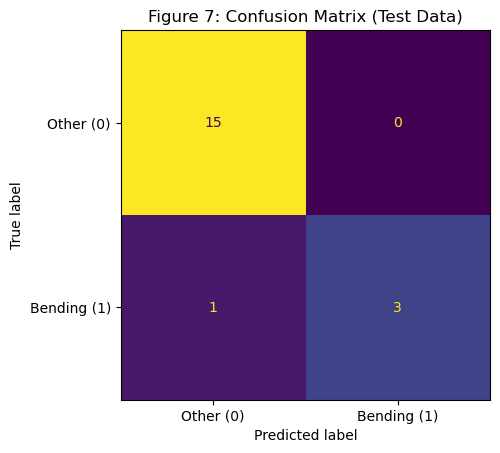

In [19]:
# Test set: break each test time series into the same l parts, then apply the scaler, RFE selection and model fit on the training data
test_class = np.where(test_instances["activity"].str.startswith("bending"), "Bending", "Other")
y_test = (test_class == "Bending").astype(int)

X_test_best = split_tables[best_l].loc[test_instances.index, X_train_best.columns]
X_test_best_std = final_scaler.transform(X_test_best)
test_prob = final_model.predict_proba(X_test_best_std[:, final_rfe.support_])[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

test_accuracy = (test_pred == y_test).mean()
best_cv_accuracy = ranked.iloc[0]["CV accuracy"]
print(f"Test instances: {len(y_test)} ({y_test.sum()} bending, {len(y_test) - y_test.sum()} other)")
print(f"Test accuracy = {test_accuracy:.4f}, test AUC = {roc_auc_score(y_test, test_prob):.4f}")
print(f"5-fold CV accuracy (l = {best_l}, p = {best_p}) = {best_cv_accuracy:.4f}")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, test_pred), display_labels=["Other (0)", "Bending (1)"]
).plot(colorbar=False)
plt.title("Figure 7: Confusion Matrix (Test Data)")
plt.show()

The test set has 19 instances (4 bending and 15 other). The classifier gets 18 of them right, a test accuracy of 94.7%, compared to the 98.6% CV accuracy from 2 a) iii. The one error is `bending2/dataset2`, a bending instance that the model gives a probability of almost 0, which also lowers the test AUC to 0.85.

The two accuracies are close: the difference is one instance, and each test instance is worth 5.3 percentage points. Both estimates are somewhat optimistic. The CV accuracy is the best of 398 (l, p) pairs, so part of it is luck in the selection. Three of the 15 other test instances (`cycling/dataset1`, `lying/dataset1`, `lying/dataset3`) are exact copies of training instances (see 1 a)), which makes them easy to classify.

## Question 2 a) vi

In [20]:
# Signed margin: positive when an instance is on the correct side of the fitted decision boundary
X_selected = X_train_best_std[:, final_rfe.support_]
train_scores = final_model.decision_function(X_selected)
margin = (2 * y_train - 1) * train_scores
print(f"Training instances on the correct side of the boundary: {(margin > 0).sum()} of {len(margin)}")
print(f"Smallest margin: {margin.min():.3f}")


def log_likelihood(scores, y):
    return -np.sum(np.logaddexp(0, -(2 * y - 1) * scores))  # numerically stable log(sigmoid)


# If the classes are separable, multiplying all coefficients (and the intercept) by c > 1 always increases
# the likelihood, so it has no finite maximum and the estimates are not stable
scales = [0.5, 1, 2, 4, 8, 16]
pd.DataFrame({
    "Scale c": scales,
    "Norm of coefficients": [c * np.linalg.norm(final_model.coef_) for c in scales],
    "Training log-likelihood": [log_likelihood(c * train_scores, y_train) for c in scales],
}).set_index("Scale c").round(6)

Training instances on the correct side of the boundary: 69 of 69
Smallest margin: 6.571


,Norm of coefficients,Training log-likelihood
Scale c,,
0.5,3.612686,-0.535280
1.0,7.225372,-0.009339
2.0,14.450745,-0.000006
4.0,28.901489,-0.000000
8.0,57.802979,-0.000000
16.0,115.605958,-0.000000


Yes. With the l = 19 features chosen by RFE, the two classes are perfectly separated in the training data: every training instance is on the correct side of the decision boundary. In that case, scaling all the coefficients up always increases the likelihood (the table above), so the maximum likelihood estimates do not exist and the coefficients would grow without bound. The solver stops at finite values only because the likelihood stops changing within floating-point precision. That is why the coefficients in 2 a) iv depend on where the solver stopped, and why their standard errors and p-values are not meaningful. The predictions are still usable, since any large enough multiple of a separating boundary gives the same classifications.

## Question 2 a) vii

In [21]:
# Class balance in the training and test sets
pd.DataFrame({
    "Training": pd.Series(train_class).value_counts(),
    "Test": pd.Series(test_class).value_counts(),
}).assign(**{"Training share": lambda d: (d["Training"] / d["Training"].sum()).round(3)})

,Training,Test,Training share
Other,60,15,0.87
Bending,9,4,0.13


In [22]:
# Case-control sampling: keep all 9 bending instances (cases) and draw the same number of other instances (controls)
rng_case_control = np.random.default_rng(552)
cases = np.flatnonzero(y_train == 1)
controls = rng_case_control.choice(np.flatnonzero(y_train == 0), size=len(cases), replace=False)
case_control_index = np.r_[cases, controls]

X_case_control = X_selected[case_control_index]
y_case_control = y_train[case_control_index]

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    case_control_model = make_logistic().fit(X_case_control, y_case_control)

# Adjust the intercept for the sampling: beta0 + log(pi / (1 - pi)) - log(pi_s / (1 - pi_s)),
# pi = share of bending in the training set, pi_s = share of bending in the case-control sample
pi = y_train.mean()
pi_sample = y_case_control.mean()
intercept_before = case_control_model.intercept_[0]
case_control_model.intercept_ = case_control_model.intercept_ + np.log(pi / (1 - pi)) - np.log(pi_sample / (1 - pi_sample))

print(f"Case-control sample: {len(cases)} bending + {len(controls)} other")
print(f"pi = {pi:.4f}, pi_sample = {pi_sample:.4f}")
print(f"Intercept before adjustment = {intercept_before:.4f}, after = {case_control_model.intercept_[0]:.4f}")
pd.DataFrame(
    {"Coefficient (beta)": np.r_[case_control_model.intercept_, case_control_model.coef_.ravel()]},
    index=["Intercept (adjusted)", *selected_features],
).round(4)

Case-control sample: 9 bending + 9 other
pi = 0.1304, pi_sample = 0.5000
Intercept before adjustment = -7.8595, after = -9.7566


,Coefficient (beta)
Intercept (adjusted),-9.7566
mean5_part3,4.6604
max5_part3,2.2988
max1_part11,-3.0231
std4_part14,-3.4561
std5_part18,-3.2210
std5_part19,1.4445


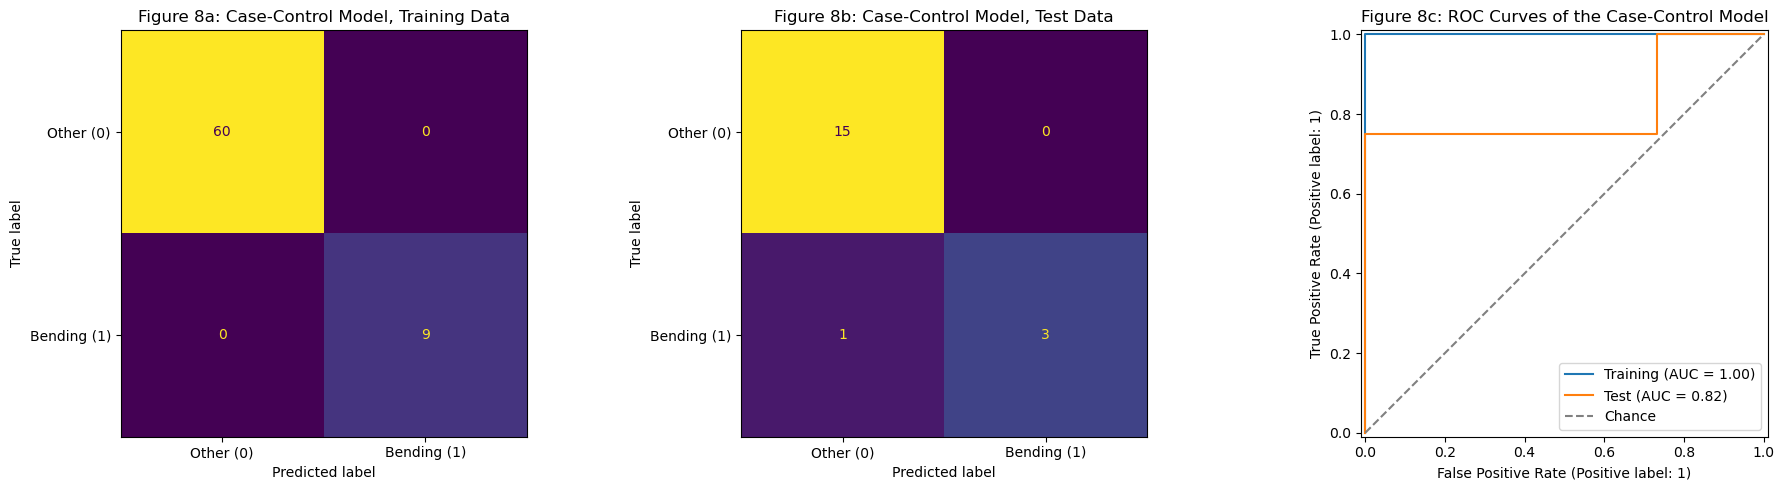

,Accuracy,AUC
Training,1.0000,1.0000
Test,0.9474,0.8167


In [23]:
# Confusion matrices and ROC curves of the case-control model on the full training set and the test set
cc_results = {}
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (label, X_eval, y_eval) in zip(
    axes[:2],
    [("Training", X_selected, y_train), ("Test", X_test_best_std[:, final_rfe.support_], y_test)],
):
    prob = case_control_model.predict_proba(X_eval)[:, 1]
    pred = (prob >= 0.5).astype(int)
    cc_results[label] = {"Accuracy": (pred == y_eval).mean(), "AUC": roc_auc_score(y_eval, prob)}
    ConfusionMatrixDisplay(confusion_matrix(y_eval, pred), display_labels=["Other (0)", "Bending (1)"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"Figure 8{'a' if label == 'Training' else 'b'}: Case-Control Model, {label} Data")
    RocCurveDisplay.from_predictions(y_eval, prob, name=label, ax=axes[2])
axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[2].set_title("Figure 8c: ROC Curves of the Case-Control Model")
axes[2].legend(loc="lower right")
plt.tight_layout()
plt.show()

pd.DataFrame(cc_results).T.round(4)

Yes, the classes are imbalanced: only 9 of the 69 training instances (13%) and 4 of the 19 test instances are bending. The confusion matrices in 2 a) iv and v show no false positives at all and only one missed bending instance, but with this imbalance a model can reach 87% accuracy by always predicting other.

The case-control model keeps all 9 bending instances (cases) and draws 9 of the 60 other instances at random (controls), using the l = 19 features selected in 2 a) iii. The sample is balanced (pi_sample = 0.5), but the real share of bending is pi = 0.13, so the intercept is adjusted by log(pi / (1 - pi)) - log(pi_sample / (1 - pi_sample)), from -7.86 to -9.76. The other coefficients are not changed.

The case-control model classifies every training instance correctly (AUC 1.0) and gets 18 of 19 test instances right (94.7%, AUC 0.82), the same accuracy as the model fit on all the training data. Case-control sampling does not help here. The full model already separates the training classes, and the case-control model is fit on only 18 instances, so it throws away 51 of the 60 controls, and its coefficients depend on which controls were drawn.

## Question 2 b) i

In [24]:
# CV accuracy of one model over the given folds. Standardization (when used) is fit on the training part of each fold only.
def fold_accuracy(make_model, X, y, folds, scale=True):
    scores = []
    for fit_idx, val_idx in folds:
        X_fit, X_val = X[fit_idx], X[val_idx]
        if scale:
            scaler = StandardScaler().fit(X_fit)
            X_fit, X_val = scaler.transform(X_fit), scaler.transform(X_val)
        scores.append(make_model().fit(X_fit, y[fit_idx]).score(X_val, y[val_idx]))
    return np.mean(scores), np.std(scores)


# CV accuracy for one value of l and every value of C
def cv_over_C(l, X, y, folds, model_for_C, C_values):
    rows = []
    with threadpool_limits(1), warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        for C in C_values:
            mean, std = fold_accuracy(lambda: model_for_C(C), X, y, folds)
            rows.append({"l": l, "C": C, "CV accuracy": mean, "CV accuracy std": std})
    return rows


def l1_binary_logistic(C):
    return LogisticRegression(penalty="l1", solver="liblinear", C=C)  # liblinear, as recommended in footnote 9


# Same stratified folds as 2 a) iii; C = 1 / lambda is the budget, so a small C means a strong L1 penalty
C_values_binary = np.logspace(-2, 4, 25)
l1_rows = Parallel(n_jobs=-1)(
    delayed(cv_over_C)(l, split_tables[l].loc[train_instances.index].to_numpy(), y_train, folds, l1_binary_logistic, C_values_binary)
    for l in l_values
)
l1_cv_results = pd.DataFrame([row for rows in l1_rows for row in rows])

# Best pair: highest CV accuracy; ties go to the smallest l, then the smallest C (the sparsest model)
l1_ranked = l1_cv_results.sort_values(["CV accuracy", "l", "C"], ascending=[False, True, True])
l1_best_l, l1_best_C = int(l1_ranked.iloc[0]["l"]), l1_ranked.iloc[0]["C"]
print(f"Best (l, C) = ({l1_best_l}, {l1_best_C:.4g}), CV accuracy = {l1_ranked.iloc[0]['CV accuracy']:.4f}")
l1_ranked.head(10).round(4)

Best (l, C) = (12, 0.5623), CV accuracy = 0.9857


,l,C,CV accuracy,CV accuracy std
282,12,0.5623,0.9857,0.0286
283,12,1.0000,0.9857,0.0286
284,12,1.7783,0.9857,0.0286
436,18,5.6234,0.9857,0.0286
459,19,1.7783,0.9857,0.0286
460,19,3.1623,0.9857,0.0286
461,19,5.6234,0.9857,0.0286
462,19,10.0000,0.9857,0.0286
463,19,17.7828,0.9857,0.0286
5,1,0.1778,0.9714,0.0350


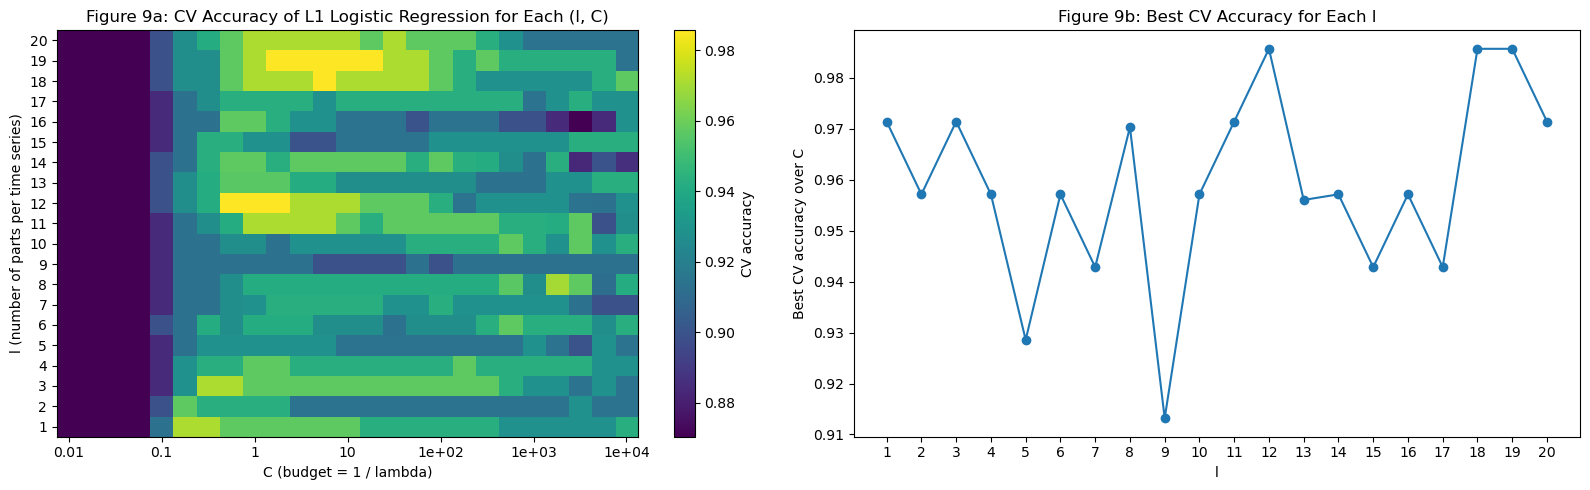

In [25]:
# Best CV accuracy over C for each l
best_by_l = l1_cv_results.groupby("l")["CV accuracy"].max()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
grid = l1_cv_results.pivot(index="l", columns="C", values="CV accuracy")
image = axes[0].imshow(grid, cmap="viridis", aspect="auto", origin="lower")
axes[0].set_xticks(range(0, len(grid.columns), 4), labels=[f"{c:.2g}" for c in grid.columns[::4]])
axes[0].set_yticks(range(len(grid.index)), labels=grid.index)
axes[0].set_xlabel("C (budget = 1 / lambda)")
axes[0].set_ylabel("l (number of parts per time series)")
axes[0].set_title("Figure 9a: CV Accuracy of L1 Logistic Regression for Each (l, C)")
fig.colorbar(image, ax=axes[0], label="CV accuracy")
axes[1].plot(best_by_l.index, best_by_l.values, marker="o")
axes[1].set_xticks(list(l_values))
axes[1].set_xlabel("l")
axes[1].set_ylabel("Best CV accuracy over C")
axes[1].set_title("Figure 9b: Best CV Accuracy for Each l")
plt.tight_layout()
plt.show()

5 of 216 coefficients are nonzero


,Coefficient (beta)
mean5_part2,1.8547
std3_part3,0.0153
max1_part7,-0.5211
mean5_part11,0.1884
max6_part11,-0.4901


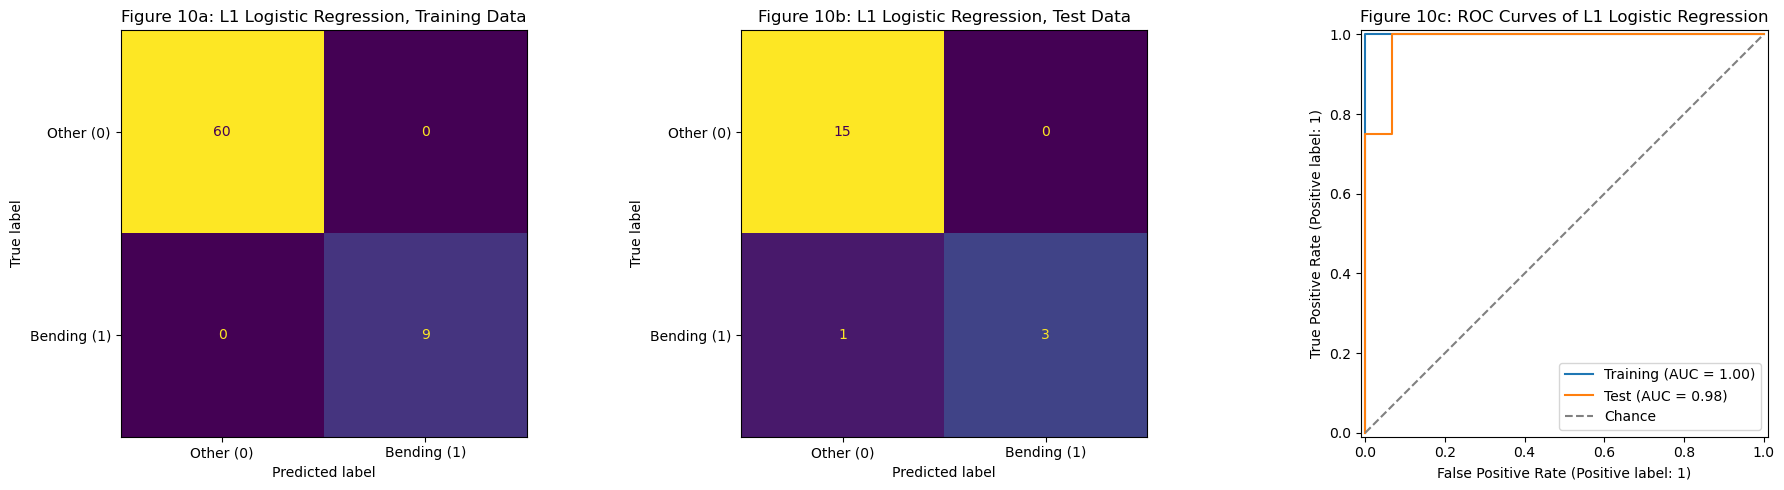

,Accuracy,AUC
Training,1.0000,1.0000
Test,0.9474,0.9833


In [26]:
# Refit on the full training set with the best (l, C), then evaluate on the training and test sets
X_train_l1 = split_tables[l1_best_l].loc[train_instances.index]
X_test_l1 = split_tables[l1_best_l].loc[test_instances.index, X_train_l1.columns]
l1_scaler = StandardScaler().fit(X_train_l1)
l1_model = l1_binary_logistic(l1_best_C).fit(l1_scaler.transform(X_train_l1), y_train)

l1_coefficients = pd.Series(l1_model.coef_.ravel(), index=X_train_l1.columns)
nonzero = l1_coefficients[l1_coefficients != 0]
print(f"{len(nonzero)} of {len(l1_coefficients)} coefficients are nonzero")
display(nonzero.to_frame("Coefficient (beta)").round(4))

l1_results = {}
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (label, X_eval, y_eval) in zip(axes[:2], [("Training", X_train_l1, y_train), ("Test", X_test_l1, y_test)]):
    prob = l1_model.predict_proba(l1_scaler.transform(X_eval))[:, 1]
    pred = (prob >= 0.5).astype(int)
    l1_results[label] = {"Accuracy": (pred == y_eval).mean(), "AUC": roc_auc_score(y_eval, prob)}
    ConfusionMatrixDisplay(confusion_matrix(y_eval, pred), display_labels=["Other (0)", "Bending (1)"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"Figure 10{'a' if label == 'Training' else 'b'}: L1 Logistic Regression, {label} Data")
    RocCurveDisplay.from_predictions(y_eval, prob, name=label, ax=axes[2])
axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[2].set_title("Figure 10c: ROC Curves of L1 Logistic Regression")
axes[2].legend(loc="lower right")
plt.tight_layout()
plt.show()

pd.DataFrame(l1_results).T.round(4)

The L1 model is cross-validated over l = 1 to 20 and 25 values of C (the budget, C = 1/lambda) from 0.01 to 10,000, with the same stratified folds as 2 a) iii. Standardization is fit inside each fold.

- The best pair is **l = 12, C = 0.56**, with a CV accuracy of 98.6%. A few other pairs (l = 18 and 19) tie at 98.6%, so ties go to the smallest l and then the smallest C, which is the sparsest model.
- With C ≤ 0.056 the penalty sets every coefficient to 0 and the model predicts other for everything (87% accuracy, the dark band on the left of Figure 9a).
- The final model keeps only **5 of the 216 features**. `mean5_part2` (the mean of `avg_rss23`) has by far the largest coefficient, which matches the boxplots in 1 c) iv, where series 5 picks out the bending instances.
- It classifies all training instances correctly (AUC 1.0). On the test set it gets 18 of 19 right (94.7%, AUC 0.98), missing one bending instance with no false positives.

## Question 2 b) ii

In [27]:
# Side-by-side comparison of the two binary classifiers
pd.DataFrame({
    "RFE + p-values (2 a)": {
        "l": best_l,
        "Features used": best_p,
        "CV accuracy": ranked.iloc[0]["CV accuracy"],
        "Test accuracy": test_accuracy,
        "Test AUC": roc_auc_score(y_test, test_prob),
    },
    "L1-penalized (2 b)": {
        "l": l1_best_l,
        "Features used": len(nonzero),
        "CV accuracy": l1_ranked.iloc[0]["CV accuracy"],
        "Test accuracy": l1_results["Test"]["Accuracy"],
        "Test AUC": l1_results["Test"]["AUC"],
    },
}).round(4)

,RFE + p-values (2 a),L1-penalized (2 b)
l,19.0000,12.0000
Features used,6.0000,5.0000
CV accuracy,0.9857,0.9857
Test accuracy,0.9474,0.9474
Test AUC,0.8500,0.9833


**Performance.** Both models reach the same CV accuracy (98.6%) and the same test accuracy (94.7%, one bending instance missed). The L1 model is somewhat better overall:
- Its test AUC is 0.98 compared to 0.85. The RFE model gives the missed bending instance a probability of almost 0, while the L1 model still ranks it above most of the other instances.
- It uses fewer features (5 vs 6).
- Its coefficients are finite and stable. The penalty stops them from growing without bound when the classes are separable, which was the problem with the unpenalized model in 2 a) vi.

**Ease of implementation.** L1 is easier. One model fit per (l, C) does variable selection and estimation together, and sklearn's liblinear solver handles it directly. The p-value approach needs a separate elimination loop (RFE) inside every fold, a refit for every value of p, and p-values computed by hand, which are not meaningful anyway when the classes are separable.

## Question 2 c) i

In [28]:
# Multiclass problem: all seven activities (bending1 and bending2 are separate classes)
y_train_multi = train_activity.to_numpy()
y_test_multi = test_instances["activity"].to_numpy()
classes = sorted(instances["activity"].unique())

# Stratified 5-fold CV. bending2 has only 4 training instances, so one fold has no bending2 instance in its validation part
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)  # sklearn warns that the smallest class has fewer than 5 members
    folds_multi = list(
        StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=552).split(np.zeros(len(y_train_multi)), y_train_multi)
    )


def l1_multinomial_logistic(C):
    # saga supports the L1 penalty for the multinomial (softmax) model
    return LogisticRegression(penalty="l1", solver="saga", C=C, max_iter=5000)


C_values_multi = np.logspace(-2, 3, 11)
multi_rows = Parallel(n_jobs=-1)(
    delayed(cv_over_C)(l, split_tables[l].loc[train_instances.index].to_numpy(), y_train_multi, folds_multi, l1_multinomial_logistic, C_values_multi)
    for l in l_values
)
multi_cv_results = pd.DataFrame([row for rows in multi_rows for row in rows])

multi_ranked = multi_cv_results.sort_values(["CV accuracy", "l", "C"], ascending=[False, True, True])
multi_best_l, multi_best_C = int(multi_ranked.iloc[0]["l"]), multi_ranked.iloc[0]["C"]
print(f"Best (l, C) = ({multi_best_l}, {multi_best_C:.4g}), CV accuracy = {multi_ranked.iloc[0]['CV accuracy']:.4f}")
multi_ranked.head(10).round(4)

Best (l, C) = (3, 100), CV accuracy = 0.9132


,l,C,CV accuracy,CV accuracy std
30,3,100.0000,0.9132,0.0281
20,2,316.2278,0.9000,0.0728
21,2,1000.0000,0.9000,0.0728
4,1,1.0000,0.8989,0.0724
16,2,3.1623,0.8989,0.0342
31,3,316.2278,0.8989,0.0342
32,3,1000.0000,0.8989,0.0342
53,5,316.2278,0.8989,0.0342
54,5,1000.0000,0.8989,0.0342
64,6,316.2278,0.8989,0.0342


Nonzero coefficients: 211 of 378


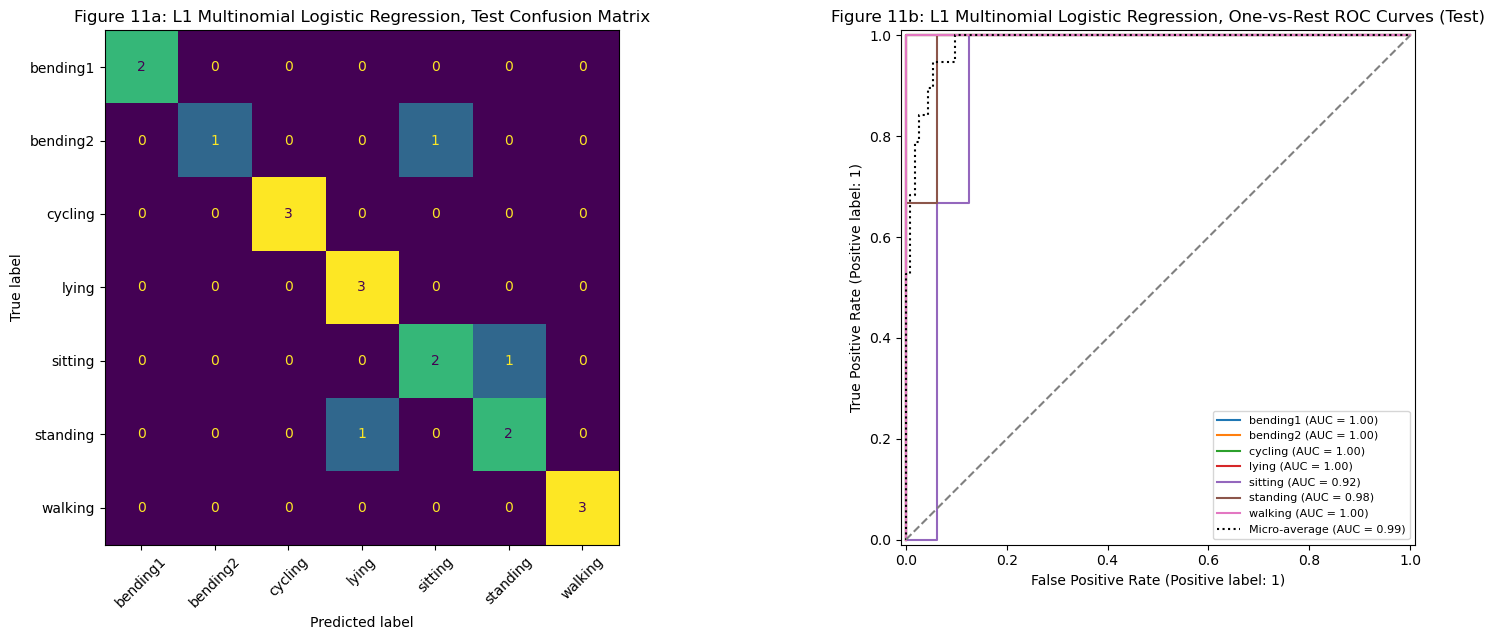

,L1 multinomial logistic
Test accuracy,0.8421
Test error,0.1579
Macro AUC (one-vs-rest),0.9851
Micro AUC,0.9852


In [29]:
# Test confusion matrix and one-vs-rest ROC curves for a multiclass model
def multiclass_report(model, X_test, figure_label, model_name):
    prob = model.predict_proba(X_test)
    pred = model.classes_[prob.argmax(axis=1)]
    y_test_bin = label_binarize(y_test_multi, classes=model.classes_)

    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
    ConfusionMatrixDisplay(confusion_matrix(y_test_multi, pred, labels=model.classes_), display_labels=model.classes_).plot(
        ax=axes[0], colorbar=False, xticks_rotation=45
    )
    axes[0].set_title(f"Figure {figure_label}a: {model_name}, Test Confusion Matrix")
    for k, activity in enumerate(model.classes_):
        RocCurveDisplay.from_predictions(y_test_bin[:, k], prob[:, k], name=activity, ax=axes[1])
    RocCurveDisplay.from_predictions(y_test_bin.ravel(), prob.ravel(), name="Micro-average", ax=axes[1], curve_kwargs={"linestyle": ":", "color": "black"})
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[1].set_title(f"Figure {figure_label}b: {model_name}, One-vs-Rest ROC Curves (Test)")
    axes[1].legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

    accuracy = (pred == y_test_multi).mean()
    return {
        "Test accuracy": accuracy,
        "Test error": 1 - accuracy,
        "Macro AUC (one-vs-rest)": roc_auc_score(y_test_multi, prob, multi_class="ovr", labels=model.classes_),
        "Micro AUC": roc_auc_score(y_test_bin, prob, average="micro"),
    }


# Refit on the full training set with the best (l, C)
X_train_multi = split_tables[multi_best_l].loc[train_instances.index]
X_test_multi = split_tables[multi_best_l].loc[test_instances.index, X_train_multi.columns]
multi_scaler = StandardScaler().fit(X_train_multi)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    multi_model = l1_multinomial_logistic(multi_best_C).fit(multi_scaler.transform(X_train_multi), y_train_multi)
print(f"Nonzero coefficients: {(multi_model.coef_ != 0).sum()} of {multi_model.coef_.size}")

multiclass_results = {}
multiclass_results["L1 multinomial logistic"] = multiclass_report(
    multi_model, multi_scaler.transform(X_test_multi), 11, "L1 Multinomial Logistic Regression"
)
pd.Series(multiclass_results["L1 multinomial logistic"]).round(4).to_frame("L1 multinomial logistic")

The L1-penalized multinomial (softmax) model is cross-validated over l and C in the same way as in 2 b) i, with stratified folds on the seven classes. The best pair is **l = 3, C = 100**, with a CV accuracy of 91.3%. The penalty at C = 100 is weak, and 217 of the 378 coefficients are nonzero.

**Test error: 3 of 19 instances are misclassified, a test error of 15.8%** (accuracy 84.2%). The errors are all among the still activities: one bending2 predicted as sitting, one sitting predicted as standing, and one standing predicted as lying. Bending1, cycling, lying and walking are all classified correctly.

**Multiclass confusion matrix and ROC.** For K classes the confusion matrix is K × K, with row i and column j counting the instances of true class i predicted as class j, so correct predictions are on the diagonal. An ROC curve needs a binary problem, so the usual approach is **one-vs-rest**: for each class k, treat k as positive and every other class as negative, and draw the ROC curve of the predicted probability of class k. The per-class AUCs can be averaged (macro AUC, 0.985 here), or all class/instance pairs can be pooled into a single curve (micro-average, AUC 0.985). The test set has only 2 or 3 instances per class, so the individual curves are very coarse.

## Question 2 c) ii

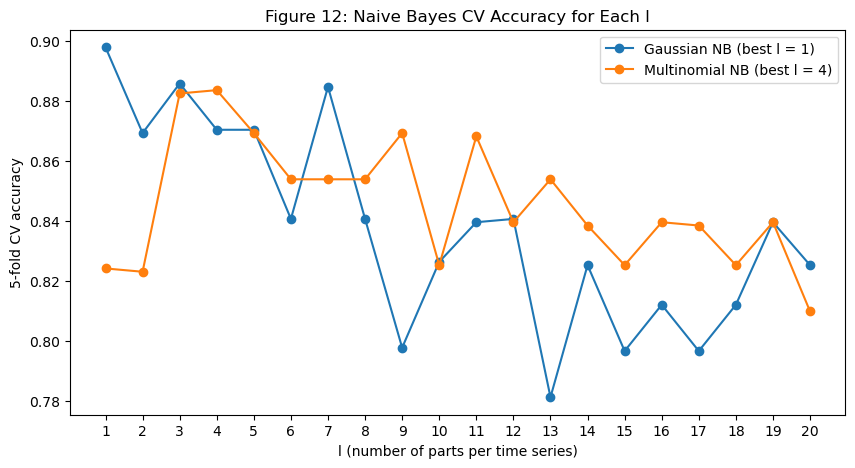

,l,CV accuracy,CV accuracy std
Model,,,
Gaussian NB,1,0.8978,0.0743
Multinomial NB,4,0.8835,0.0584


In [30]:
# Naive Bayes: choose l by the same stratified 5-fold CV (no penalty to tune). Features are used without standardization:
# Gaussian NB does not need it, and Multinomial NB needs non-negative features (mean, std and max of RSS are all >= 0)
def cv_naive_bayes(l, X, y):
    with threadpool_limits(1):
        rows = []
        for name, make_model in [("Gaussian NB", GaussianNB), ("Multinomial NB", MultinomialNB)]:
            mean, std = fold_accuracy(make_model, X, y, folds_multi, scale=False)
            rows.append({"Model": name, "l": l, "CV accuracy": mean, "CV accuracy std": std})
        return rows


nb_rows = Parallel(n_jobs=-1)(
    delayed(cv_naive_bayes)(l, split_tables[l].loc[train_instances.index].to_numpy(), y_train_multi) for l in l_values
)
nb_cv_results = pd.DataFrame([row for rows in nb_rows for row in rows])

nb_best = (
    nb_cv_results.sort_values(["CV accuracy", "l"], ascending=[False, True]).groupby("Model").head(1).set_index("Model")
)

fig, ax = plt.subplots(figsize=(10, 5))
for name, group in nb_cv_results.groupby("Model"):
    ax.plot(group["l"], group["CV accuracy"], marker="o", label=f"{name} (best l = {int(nb_best.loc[name, 'l'])})")
ax.set_xticks(list(l_values))
ax.set_xlabel("l (number of parts per time series)")
ax.set_ylabel("5-fold CV accuracy")
ax.set_title("Figure 12: Naive Bayes CV Accuracy for Each l")
ax.legend()
plt.show()
nb_best.round(4)

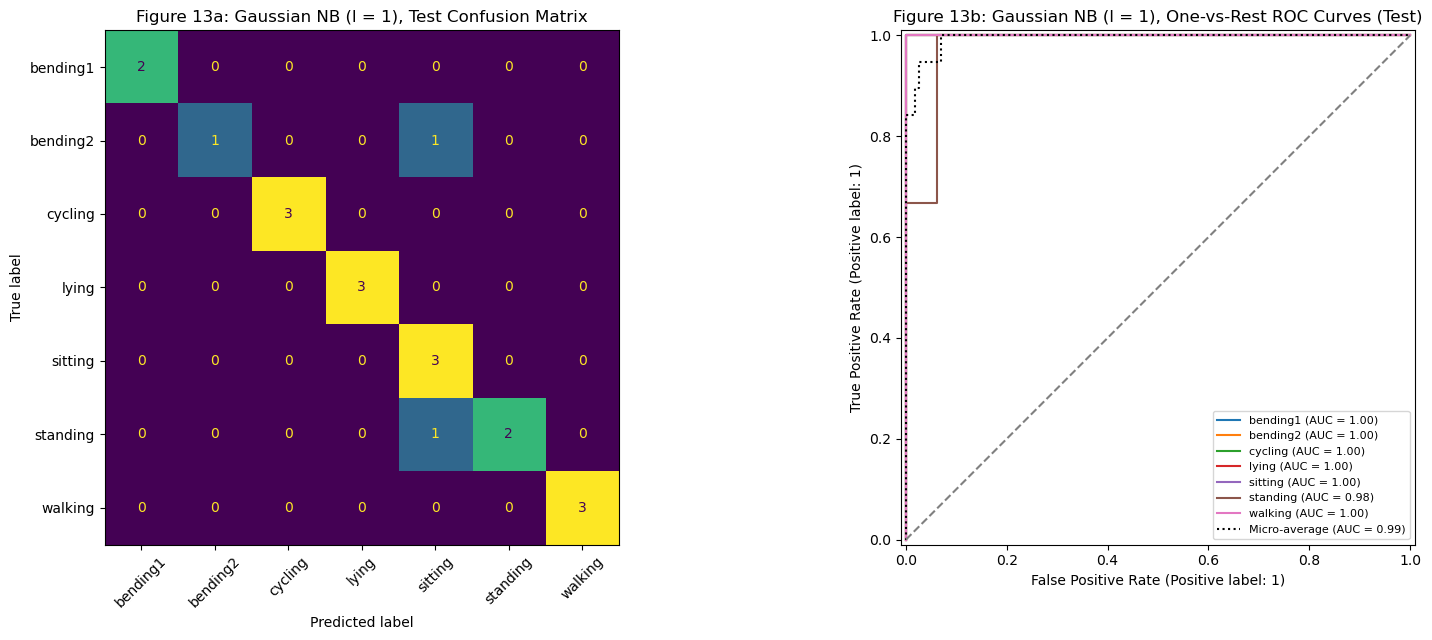

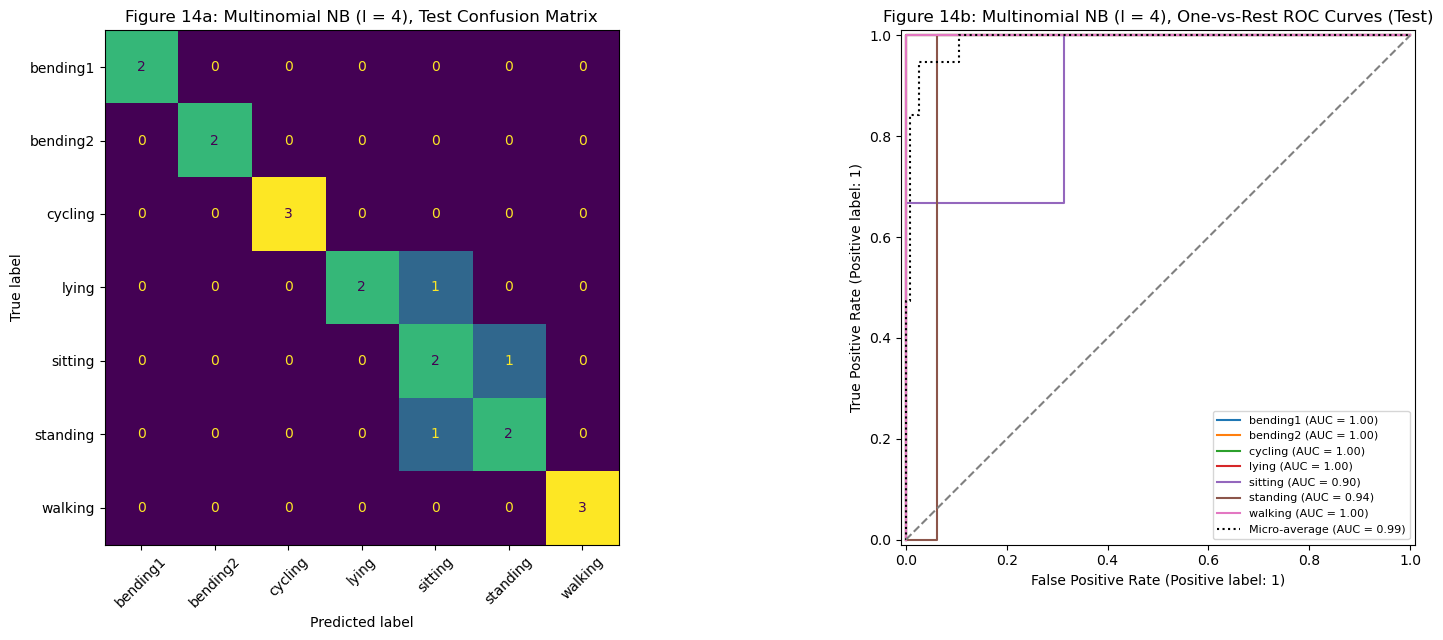

,Test accuracy,Test error,Macro AUC (one-vs-rest),Micro AUC
L1 multinomial logistic,0.8421,0.1579,0.9851,0.9852
Gaussian NB,0.8947,0.1053,0.9970,0.9940
Multinomial NB,0.8421,0.1579,0.9762,0.9885


In [31]:
# Refit each Naive Bayes model on the full training set with its best l and evaluate on the test set
for figure_label, (name, make_model) in zip([13, 14], [("Gaussian NB", GaussianNB), ("Multinomial NB", MultinomialNB)]):
    l = int(nb_best.loc[name, "l"])
    X_train_nb = split_tables[l].loc[train_instances.index]
    X_test_nb = split_tables[l].loc[test_instances.index, X_train_nb.columns]
    model = make_model().fit(X_train_nb, y_train_multi)
    multiclass_results[name] = multiclass_report(model, X_test_nb, figure_label, f"{name} (l = {l})")

pd.DataFrame(multiclass_results).T.round(4)

l is chosen by the same stratified 5-fold CV (Figure 12). Naive Bayes has no penalty to tune.

| Model | Best l | CV accuracy | Test errors | Test error | Macro AUC |
|---|---|---|---|---|---|
| Gaussian NB | 1 | 89.8% | 2 of 19 | 10.5% | 0.997 |
| Multinomial NB | 4 | 88.4% | 3 of 19 | 15.8% | 0.976 |

**Gaussian NB** misclassifies one bending2 as sitting and one standing as sitting. **Multinomial NB** confuses lying, sitting and standing (three errors among them).

Gaussian NB does better. It models each feature within each class with its own normal distribution, which suits continuous measurements like these. Multinomial NB is designed for counts (such as word counts): each feature value acts as a count that multiplies the log of that feature's class-specific frequency. Features with large values (the average RSS features, around 15 to 45) therefore dominate the likelihood over features with small values (the variance features, mostly below 5), whether or not they are more informative, which is a poor fit for this data.

## Question 2 c) iii

In [32]:
# All three multiclass models
summary = pd.DataFrame(multiclass_results).T
summary.insert(0, "l", [multi_best_l, int(nb_best.loc["Gaussian NB", "l"]), int(nb_best.loc["Multinomial NB", "l"])])
summary.insert(1, "CV accuracy", [
    multi_ranked.iloc[0]["CV accuracy"], nb_best.loc["Gaussian NB", "CV accuracy"], nb_best.loc["Multinomial NB", "CV accuracy"]
])
summary.round(4)

,l,CV accuracy,Test accuracy,Test error,Macro AUC (one-vs-rest),Micro AUC
L1 multinomial logistic,3,0.9132,0.8421,0.1579,0.9851,0.9852
Gaussian NB,1,0.8978,0.8947,0.1053,0.9970,0.9940
Multinomial NB,4,0.8835,0.8421,0.1579,0.9762,0.9885


**Gaussian Naive Bayes is the best choice for this problem.** It has the lowest test error (10.5%, 2 of 19 misclassified) and the highest test AUC (0.997). It is also the simplest model: there is no penalty to tune, it uses only l = 1 (18 features), and it trains instantly.

The L1 multinomial logistic regression had the highest CV accuracy (91.3% vs 89.8%) and a test error of 15.8%, so it is close. The differences between the three models are one test instance, so the comparison is not decisive with only 19 test instances. All three models make their mistakes on the same kind of instances: the still activities (sitting, standing, lying, and bending2), whose RSS signals look alike. The moving activities (cycling and walking) and bending1 are always classified correctly.

# Question 3
ISLR 4.8.3

With one feature and $X \mid Y = k \sim N(\mu_k, \sigma_k^2)$, the Bayes classifier assigns $x$ to the class with the largest posterior probability

$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left(-\frac{(x - \mu_k)^2}{2\sigma_k^2}\right).$$

The denominator is the same for every class, so this is the same as choosing the class with the largest $\pi_k f_k(x)$, or the largest $\log(\pi_k f_k(x))$. Dropping the constant $-\frac{1}{2}\log(2\pi)$, which is the same for every class, the discriminant function is

$$\delta_k(x) = \log \pi_k - \log \sigma_k - \frac{(x - \mu_k)^2}{2\sigma_k^2} = -\frac{1}{2\sigma_k^2}\,x^2 + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} + \log \pi_k - \log \sigma_k.$$

In LDA every class has the same variance $\sigma^2$, so the $x^2$ term $-\frac{x^2}{2\sigma^2}$ is the same for every class and can be dropped, which leaves a discriminant that is linear in $x$. Here each class has its own $\sigma_k^2$, so the coefficient of $x^2$, $-\frac{1}{2\sigma_k^2}$, is different for each class and cannot be dropped. The boundary between classes $k$ and $l$ is where $\delta_k(x) = \delta_l(x)$:

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right) x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right) x + \left(\frac{\mu_l^2}{2\sigma_l^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log\frac{\pi_k}{\pi_l} + \log\frac{\sigma_l}{\sigma_k}\right) = 0.$$

When $\sigma_k \neq \sigma_l$, the coefficient of $x^2$ is not zero, so the Bayes classifier is not linear in $x$. Each $\delta_k(x)$ is a quadratic function of $x$, and the decision boundaries are the roots of a quadratic equation, so the Bayes classifier is quadratic.

# Question 4
ISLR 4.8.7

Let $\pi_{\text{Yes}} = 0.8$, $\pi_{\text{No}} = 0.2$, $\mu_{\text{Yes}} = 10$, $\mu_{\text{No}} = 0$ and $\sigma^2 = 36$ for both classes. By Bayes' theorem,

$$P(\text{Yes} \mid X = 4) = \frac{\pi_{\text{Yes}} f_{\text{Yes}}(4)}{\pi_{\text{Yes}} f_{\text{Yes}}(4) + \pi_{\text{No}} f_{\text{No}}(4)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi \sigma^2}} \exp\left(-\frac{(x - \mu_k)^2}{2\sigma^2}\right).$$

Both classes have the same variance, so the factor $\frac{1}{\sqrt{2\pi\sigma^2}}$ cancels:

$$P(\text{Yes} \mid X = 4) = \frac{0.8\, e^{-(4 - 10)^2 / 72}}{0.8\, e^{-(4 - 10)^2 / 72} + 0.2\, e^{-(4 - 0)^2 / 72}} = \frac{0.8\, e^{-0.5}}{0.8\, e^{-0.5} + 0.2\, e^{-0.2222}} = \frac{0.8 \times 0.6065}{0.8 \times 0.6065 + 0.2 \times 0.8007} = \frac{0.4852}{0.6454} \approx 0.752.$$

The probability that the company issues a dividend this year is about **75.2%**.

In [33]:
# Check the Question 4 answer numerically
prior = {"Yes": 0.8, "No": 0.2}
class_means = {"Yes": 10, "No": 0}
weighted = {k: prior[k] * norm.pdf(4, loc=class_means[k], scale=np.sqrt(36)) for k in prior}
print(f"P(Yes | X = 4) = {weighted['Yes'] / sum(weighted.values()):.4f}")

P(Yes | X = 4) = 0.7519


## References
- AReM data set (UCI Machine Learning Repository): https://archive.ics.uci.edu/dataset/366/activity+recognition+system+based+on+multisensor+data+fusion+arem
- James, Witten, Hastie, Tibshirani, *An Introduction to Statistical Learning* (ISLR), Section 5.2 (the bootstrap) and Chapter 4 (classification; Section 4.4 for LDA, QDA and Bayes' theorem in Questions 3 and 4)
- `numpy.percentile` (percentile bootstrap interval): https://numpy.org/doc/stable/reference/generated/numpy.percentile.html
- `numpy.array_split` (splitting each time series into parts of approximately equal length): https://numpy.org/doc/stable/reference/generated/numpy.array_split.html
- `scipy.stats.f_oneway` (one-way ANOVA F-statistic): https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html
- `pandas.read_csv` (regular expression separators and comment lines): https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
- `seaborn.pairplot` (scatter plot matrices): https://seaborn.pydata.org/generated/seaborn.pairplot.html
- Hastie, Tibshirani, Friedman, *The Elements of Statistical Learning*, Section 7.10.2 (the wrong and right way to do cross-validation)
- `sklearn.feature_selection.RFE`: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html
- `sklearn.model_selection.StratifiedKFold` (stratified cross-validation): https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
- `sklearn.linear_model.LogisticRegression`: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- `sklearn.metrics.RocCurveDisplay` and `ConfusionMatrixDisplay`: https://scikit-learn.org/stable/modules/model_evaluation.html
- `threadpoolctl` (limiting BLAS threads for many small model fits): https://github.com/joblib/threadpoolctl
- Case-control sampling and the intercept adjustment: Hastie and Tibshirani, *Statistical Learning* course slides for ISLR Chapter 4 (case-control sampling and logistic regression)
- `sklearn.linear_model.LogisticRegression` solvers (liblinear for binary L1, saga for multinomial L1): https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
- Multiclass ROC curves (one-vs-rest and micro-averaging): https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html
- `sklearn.naive_bayes` (Gaussian and Multinomial Naive Bayes): https://scikit-learn.org/stable/modules/naive_bayes.html